<a href="https://colab.research.google.com/github/likhithapotluri/Group04_AAI520_Project/blob/main/AAI_520_Final_Project_Group_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📈 Autonomous Multi-Agent Investment Research & Financial Analysis System

**Team:** Harsh Modi · Jaiganesh Nagabooshanam · Likhitha Potluri
**GitHub Repository:** http://github.com/likhithapotluri/Group04_AAI520_Project

## Objective
An autonomous multi-agent system that researches any US-listed stock from start to finish and
produces a grounded **BUY / HOLD / SELL** recommendation with a full research note.

Specialized agents:
- **Plan** their own research steps (goal decomposition)
- **Choose and call tools** at runtime (Yahoo Finance, FRED, news, SEC EDGAR)
- **Critique and revise** their output before it is shown (Evaluator–Optimizer)
- **Remember** earlier runs and **learn** from whether past calls were right (SQLite memory)

## Three Workflow Patterns
| # | Pattern | Implementation |
|---|---|---|
| 1 | **Prompt Chaining** | News: Ingest → Preprocess → Sentiment → Entities → Summary |
| 2 | **Specialist Routing** | A supervisor sends each research task to the Market, Earnings/Filings or News agent |
| 3 | **Evaluator–Optimizer** | An evaluator scores each draft for grounding and hallucinations, and the writer revises it until it passes |

## System Flow
```
User input ─► ✅ Input Validator ─► 🧠 Recall Memory ─► 📋 Planner ─► 🧭 Router
                                                           ├─► 📊 Market Analyzer
                                                           ├─► 📑 Earnings/Filings
                                                           └─► 📰 News Agent (Prompt Chain)
          ─► ✍️ Writer ⇄ 🔍 Evaluator + 🪞 Self-Reflection ─► ✅ Recommendation
          ─► 💾 Save to Memory ─► 📏 Score past calls against actual prices
```

## Runs With or Without API Keys
| Backend | When it's used | Reasoning engine |
|---|---|---|
| `gemini` | Gemini key in Colab Secrets | Google Gemini |
| `local` | No key, GPU runtime | Qwen2.5-1.5B-Instruct (open source, runs in Colab) |
| `offline` | No key, no GPU | Rule-based engine plus FinBERT sentiment |

## Data Sources (all free)
| Source | Data | Key needed? |
|---|---|---|
| Yahoo Finance | OHLCV, fundamentals, earnings, news | No |
| FRED | 10Y yield, CPI, Fed Funds, unemployment | No (public CSV) |
| NewsAPI | Headlines | Optional |
| SEC EDGAR | 10-K / 10-Q MD&A | No key, just a name and email as User-Agent |


> ⚠️ **Disclaimer:** academic project, **not financial advice**.

**How to run:** Runtime → Run all. API keys are optional.


In [1]:
import importlib.metadata as md
import re
import subprocess

required = next((r for r in md.requires("google-colab") or []
                 if r.lower().startswith("google-auth")), "not pinned")
print("google-auth installed :", md.version("google-auth"))
print("google-colab requires :", required)
print("google-genai installed:", md.version("google-genai"))

# Show only conflicts involving the packages we touched
check = subprocess.run(["pip", "check"], capture_output=True, text=True).stdout
ours = re.compile(r"google-auth|google-genai|yfinance|fredapi|tenacity|beautifulsoup4|lxml", re.I)
conflicts = [line for line in check.splitlines() if ours.search(line)]
print("\n✅ No conflicts from our installs" if not conflicts else "\n⚠️ " + "\n".join(conflicts))


google-auth installed : 2.49.0
google-colab requires : google-auth==2.49.0
google-genai installed: 2.12.1

✅ No conflicts from our installs


## 2️⃣ Imports, Configuration & Backend Selection

**Purpose:** Load libraries, set up logging and warnings, and gather every setting in one
`Config` object.

### Key pieces
- **`get_secret()`** reads keys from Colab Secrets, then from environment variables, and returns
  `None` if there's no key. Nothing is hard-coded and nothing crashes
- **`secret_field()`** reads secrets when `Config()` is created, so a secret added later is
  picked up after re-running this cell
- **`LLM_BACKEND`** can be `"auto"` (default), `"gemini"`, `"local"` or `"offline"`
- **`SEC_USER_AGENT_OVERRIDE`** takes a name and email to turn on SEC filings. It's free and not
  a key
- **`planned_backend()`** with `"auto"`: Gemini if there's a key, local model if there's a GPU,
  otherwise offline

### Main settings
| Setting | Default | Meaning |
|---|---|---|
| `price_period` | `2y` | Price history window (1y–5y) |
| `cache_hours` | `12` | How long tool results stay cached |
| `max_eval_iterations` | `3` | Maximum number of critique-and-revise rounds |
| `quality_threshold` | `0.80` | Minimum quality score to approve a report |
| `confidence_threshold` | `0.65` | Minimum confidence to approve a call |
| `local_model` | `Qwen/Qwen2.5-1.5B-Instruct` | Free open model for the `local` backend |

### Logging and warnings
- `force=True` is needed because Colab sets up logging before the notebook runs
- Noisy HTTP loggers are quieted, and only known-harmless warnings are filtered

✅ **Expected output (no keys, CPU):** `LLM backend : offline`. That's a valid way to run the
notebook, not an error.


In [2]:
import hashlib
import io
import json
import logging
import os
import re
import sqlite3
import uuid
import warnings
from collections import Counter
from dataclasses import dataclass, field
from datetime import datetime, timedelta, timezone
from typing import Any, Callable, Dict, List, Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yfinance as yf
from bs4 import BeautifulSoup, MarkupResemblesLocatorWarning, XMLParsedAsHTMLWarning
from IPython.display import Markdown, display

# ---- Targeted warning filters: silence only known-harmless warnings ----
warnings.filterwarnings("ignore", category=MarkupResemblesLocatorWarning)
warnings.filterwarnings("ignore", category=XMLParsedAsHTMLWarning)
warnings.filterwarnings("ignore", message=".*HF_TOKEN.*")  # public HF models need no token

# ---- Logging: force=True is required in Colab (root logger is pre-configured) ----
logging.basicConfig(level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s")
for noisy in ("httpx", "httpcore", "urllib3", "yfinance", "peewee"):
    logging.getLogger(noisy).setLevel(logging.WARNING)
log = logging.getLogger("invest_agent")

# ---- Optional settings: no secrets required ----
SEC_USER_AGENT_OVERRIDE = "likhitha.potluri@sandiego.edu"
LLM_BACKEND = "auto"          # "auto" | "gemini" | "local" | "offline"


def get_secret(name: str, default: Optional[str] = None) -> Optional[str]:
    """Read from Colab Secrets first, then environment variables."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:  # not in Colab, secret missing, or notebook access not granted
        pass
    return os.environ.get(name, default)


def secret_field(name: str, fallback: Optional[str] = None):
    """Read the secret when Config() is created, not when the class is defined."""
    return field(default_factory=lambda: get_secret(name) or fallback)


def gpu_available() -> bool:
    try:
        import torch
        return torch.cuda.is_available()
    except Exception:
        return False


@dataclass
class Config:
    gemini_api_key: Optional[str] = secret_field("GEMINI_API_KEY")
    fred_api_key: Optional[str] = secret_field("FRED_API_KEY")
    news_api_key: Optional[str] = secret_field("NEWS_API_KEY")
    sec_user_agent: Optional[str] = field(
        default_factory=lambda: get_secret("SEC_USER_AGENT") or SEC_USER_AGENT_OVERRIDE or None)
    llm_backend: str = field(default_factory=lambda: LLM_BACKEND)
    model_candidates: List[str] = field(default_factory=lambda: [
    "gemini-3.5-flash-lite", "gemini-flash-latest", "gemini-3.8-flash"])
    local_model: str = "Qwen/Qwen2.5-1.5B-Instruct"  # Apache-2.0, no HF token needed
    local_max_new_tokens: int = 1536
    local_max_prompt_chars: int = 16000
    db_path: str = "/content/drive/MyDrive/agent_memory.db"
    price_period: str = "2y"                   # 1y-5y supported
    cache_hours: int = 12
    max_eval_iterations: int = 3
    quality_threshold: float = 0.80
    confidence_threshold: float = 0.65

    @property
    def sec_enabled(self) -> bool:
        ua = self.sec_user_agent or ""
        return bool(re.search(r"\S+@\S+\.\S+", ua)) and "example.com" not in ua


def planned_backend(cfg: Config) -> str:
    choice = (cfg.llm_backend or "auto").lower()
    if choice != "auto":
        return choice
    if cfg.gemini_api_key:
        return "gemini"
    return "local" if gpu_available() else "offline"


CFG = Config()
print(f"Gemini key loaded : {bool(CFG.gemini_api_key)}   (optional)")
print(f"SEC User-Agent set: {CFG.sec_enabled}   (optional: enables 10-K/10-Q MD&A)")
print(f"GPU available     : {gpu_available()}")
print(f"➡️  LLM backend     : {planned_backend(CFG)}")


Gemini key loaded : True   (optional)
SEC User-Agent set: True   (optional: enables 10-K/10-Q MD&A)
GPU available     : True
➡️  LLM backend     : gemini


## 3️⃣ Utilities & Pluggable LLM Backends

**Purpose:** Give every agent **one interface** for reasoning, whether that runs on Gemini, a
local open model or no model at all.

### Helper functions
| Function | Why it exists |
|---|---|
| `to_jsonable()` | Converts NumPy and pandas values (`np.float64`, `NaN`, `Timestamp`) into JSON-safe types |
| `safe_float()`, `as_list()`, `ensure_dict()` | Model output is unpredictable, so these stop crashes on `null`, strings or lists |
| `extract_json()` | Pulls JSON out of model text even when it's wrapped in markdown |

### Backends
| Class | What it does |
|---|---|
| `GeminiBackend` | Calls Gemini and **picks a model that's currently available** (`resolve_model`), so retired model names don't cause errors |
| `LocalHFBackend` | Runs Qwen2.5-1.5B inside Colab. It truncates long prompts but keeps the schema at the end |
| `OfflineBackend` | Has no model; every step uses its rule-based fallback |

`build_backend()` tries the backends in order and moves down a level if one fails to load (for
example, an invalid key).

### The `LLM` wrapper: graceful degradation
Every `ask_json()` call can carry a **rule-based `fallback`**:
- If the model errors, times out, returns invalid JSON or **leaves out required keys**, only that
  step falls back to rules, and the run continues
- Retries cover only temporary errors (rate limits, 5xx, network problems, bad JSON)
- `last_source` records whether each output came from the `"llm"` or from `"rules"`
- `calls` and `fallbacks` measure how much work the model did and how reliable it was

### Why it matters
The system **never depends on one provider**, and every output can be traced back to the engine
that produced it.


In [3]:
import time

try:
    import httpx
    _TRANSPORT_ERRORS: tuple = (httpx.TransportError,)
except ImportError:
    _TRANSPORT_ERRORS = ()

DEFAULT_SYSTEM = "You are a precise financial analyst."
DEFAULT_JSON_SYSTEM = "You are a precise financial analyst. Respond ONLY with valid JSON."


def to_jsonable(obj: Any) -> Any:
    """Recursively convert numpy/pandas types to JSON-safe Python types."""
    if obj is None or obj is pd.NA:
        return None
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return to_jsonable(obj.tolist())
    if isinstance(obj, (bool, np.bool_)):
        return bool(obj)
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, (float, np.floating)):
        f = float(obj)
        return round(f, 4) if np.isfinite(f) else None
    if isinstance(obj, (pd.Timestamp, datetime)):
        return None if pd.isna(obj) else obj.isoformat()
    return obj


def safe_float(x: Any, default: Optional[float] = 0.0) -> Optional[float]:
    """Convert LLM/tool output to float without crashing on None or strings."""
    try:
        f = float(x)
        return f if np.isfinite(f) else default
    except (TypeError, ValueError):
        return default


def as_list(x: Any) -> List:
    if x is None:
        return []
    return x if isinstance(x, list) else [x]


def extract_json(text: str) -> Any:
    """Robustly parse JSON from an LLM response."""
    text = re.sub(r"^```(?:json)?|```$", "", text.strip(), flags=re.M).strip()
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        match = re.search(r"(\{.*\}|\[.*\])", text, re.S)
        if match:
            return json.loads(match.group(1))
        raise


def ensure_dict(obj: Any) -> Dict:
    """LLMs occasionally return a list instead of an object."""
    if isinstance(obj, dict):
        return obj
    if isinstance(obj, list) and len(obj) == 1 and isinstance(obj[0], dict):
        return obj[0]
    return {"items": obj}


class EmptyLLMResponse(RuntimeError):
    """Raised when the model returns no usable text."""


class OfflineModeError(RuntimeError):
    """Raised when no generative model exists and no rule-based fallback was given."""


def _is_retryable(exc: BaseException) -> bool:
    code = getattr(exc, "code", None)
    if isinstance(code, int):  # Gemini APIError: retry rate limits + transient 5xx only
        return code in (429, 500, 502, 503, 504)
    return isinstance(exc, (json.JSONDecodeError, EmptyLLMResponse) + _TRANSPORT_ERRORS)


def resolve_model(client, candidates: List[str]) -> str:
    """Pick the first candidate model that actually answers a generateContent
    call. Catalog membership isn't enough — Google has been 404'ing
    generateContent on models that still show up in ListModels."""
    for m in candidates:
        try:
            client.models.generate_content(model=m, contents="ping")
            return m
        except Exception as e:
            log.warning(f"Model {m} unusable ({type(e).__name__}); trying next candidate")
    available = {m.name.split("/")[-1] for m in client.models.list() if m.name}
    flash = sorted(a for a in available if "flash" in a and not any(
        x in a for x in ("lite", "image", "tts", "live", "audio", "embedding")))
    if flash:
        log.warning(f"None of {candidates} usable; falling back to {flash[-1]}")
        return flash[-1]
    raise ValueError(f"No suitable Gemini model found. Available: {sorted(available)[:15]}")


class GeminiBackend:
    name, max_attempts, backoff_s = "gemini", 5, 4

    def __init__(self, cfg: Config):
        if not cfg.gemini_api_key:
            raise ValueError("GEMINI_API_KEY not set")
        from google import genai
        from google.genai import types
        self._types = types
        self.client = genai.Client(api_key=cfg.gemini_api_key)
        self.label = resolve_model(self.client, cfg.model_candidates)

    @staticmethod
    def _text(resp) -> str:
        cands = resp.candidates or []
        if not cands or not cands[0].content or not cands[0].content.parts:
            reason = getattr(cands[0], "finish_reason", None) if cands else "NO_CANDIDATES"
            raise EmptyLLMResponse(f"Empty response (finish_reason={reason})")
        text = "".join(p.text for p in cands[0].content.parts
                       if getattr(p, "text", None) and not getattr(p, "thought", False))
        if not text.strip():
            raise EmptyLLMResponse("Response had no text parts")
        return text

    def generate(self, prompt: str, system: str, temperature: float, json_mode: bool) -> str:
        config = self._types.GenerateContentConfig(
            temperature=temperature, system_instruction=system,
            response_mime_type="application/json" if json_mode else "text/plain")
        resp = self.client.models.generate_content(model=self.label, contents=prompt,
                                                   config=config)
        return self._text(resp)


class LocalHFBackend:
    """Free open-source model running inside Colab (no key, no token)."""
    name, max_attempts, backoff_s = "local", 2, 0

    def __init__(self, cfg: Config):
        import torch
        import transformers
        from packaging.version import Version
        from transformers import AutoModelForCausalLM, AutoTokenizer

        self.torch = torch
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        if self.device == "cpu":
            log.warning("No GPU: the local model will be very slow. Use Runtime → Change "
                        "runtime type → T4 GPU, or set LLM_BACKEND='offline'.")
        dtype = torch.float16 if self.device == "cuda" else torch.float32
        # transformers >= 4.56 renamed torch_dtype -> dtype (old name is deprecated)
        dtype_kw = ("dtype" if Version(transformers.__version__) >= Version("4.56.0")
                    else "torch_dtype")
        log.info(f"⬇️  Loading {cfg.local_model} on {self.device} (first run downloads it)...")
        self.tok = AutoTokenizer.from_pretrained(cfg.local_model)
        self.model = AutoModelForCausalLM.from_pretrained(
            cfg.local_model, **{dtype_kw: dtype}).to(self.device).eval()
        self.label = cfg.local_model
        self.max_new_tokens = cfg.local_max_new_tokens
        self.max_chars = cfg.local_max_prompt_chars

    def _shrink(self, text: str) -> str:
        """Keep head + tail so the JSON schema at the end of prompts survives truncation."""
        if len(text) <= self.max_chars:
            return text
        head = int(self.max_chars * 0.7)
        return text[:head] + "\n...[truncated]...\n" + text[-(self.max_chars - head):]

    def generate(self, prompt: str, system: str, temperature: float, json_mode: bool) -> str:
        if json_mode:
            system += " Output ONE valid JSON object only: no markdown fences, no commentary."
        msgs = [{"role": "system", "content": system},
                {"role": "user", "content": self._shrink(prompt)}]
        text = self.tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        inputs = self.tok(text, return_tensors="pt").to(self.device)
        with self.torch.inference_mode():
            out = self.model.generate(**inputs, max_new_tokens=self.max_new_tokens,
                                      do_sample=True, temperature=max(float(temperature), 0.05),
                                      top_p=0.9, pad_token_id=self.tok.eos_token_id)
        result = self.tok.decode(out[0][inputs["input_ids"].shape[1]:],
                                 skip_special_tokens=True).strip()
        if not result:
            raise EmptyLLMResponse("Local model returned nothing")
        return result


class OfflineBackend:
    name, label, max_attempts, backoff_s = "offline", "rule-based engine (no LLM)", 1, 0

    def generate(self, *args, **kwargs) -> str:
        raise OfflineModeError("Offline backend has no generative model")


def build_backend(cfg: Config):
    requested = planned_backend(cfg)
    chain = {"gemini": ["gemini", "local", "offline"],
             "local": ["local", "offline"]}.get(requested, ["offline"])
    if requested == "gemini" and not gpu_available():
        chain = ["gemini", "offline"]
    builders = {"gemini": GeminiBackend, "local": LocalHFBackend}
    for name in chain:
        if name == "offline":
            return OfflineBackend()
        try:
            return builders[name](cfg)
        except Exception as e:
            log.warning(f"{name} backend unavailable ({type(e).__name__}: {str(e)[:150]}); "
                        "trying next option")
    return OfflineBackend()


class LLM:
    """One interface for every backend. Each call can carry a rule-based fallback."""

    def __init__(self, cfg: Config):
        self.requested = planned_backend(cfg)
        self.backend = build_backend(cfg)
        self.calls = 0
        self.fallbacks = 0
        self.last_source: Optional[str] = None
        log.info(f"🤖 LLM backend: {self.backend.name} ({self.backend.label})")

    @property
    def is_offline(self) -> bool:
        return self.backend.name == "offline"

    @property
    def model(self) -> str:
        return self.backend.label

    def _complete(self, prompt: str, system: str, temperature: float, json_mode: bool) -> Any:
        attempts = self.backend.max_attempts
        for attempt in range(1, attempts + 1):
            try:
                self.calls += 1
                text = self.backend.generate(prompt, system, temperature, json_mode)
                return extract_json(text) if json_mode else text
            except Exception as e:
                if attempt >= attempts or not _is_retryable(e):
                    raise
                wait = min(60, self.backend.backoff_s * 2 ** (attempt - 1))
                log.warning(f"Retry {attempt}/{attempts - 1} after {type(e).__name__}"
                            + (f"; sleeping {wait}s" if wait else ""))
                time.sleep(wait)

    def ask_text(self, prompt: str, system: str = DEFAULT_SYSTEM,
                 temperature: float = 0.3) -> str:
        if self.is_offline:
            raise OfflineModeError("ask_text is unavailable in offline mode")
        return self._complete(prompt, system, temperature, json_mode=False)

    def ask_json(self, prompt: str, system: str = DEFAULT_JSON_SYSTEM, temperature: float = 0.1,
                 fallback: Optional[Callable[[], Dict]] = None,
                 required_keys: tuple = ()) -> Dict:
        if self.is_offline:
            if fallback is None:
                raise OfflineModeError("No rule-based fallback for this step")
            self.last_source = "rules"
            return ensure_dict(fallback())
        try:
            out = ensure_dict(self._complete(prompt, system, temperature, json_mode=True))
            missing = [k for k in required_keys if k not in out]
            if missing:
                raise ValueError(f"LLM output missing keys {missing}")
            self.last_source = "llm"
            return out
        except Exception as e:
            if fallback is None:
                raise
            self.fallbacks += 1
            self.last_source = "rules"
            log.warning(f"↩️  LLM step failed ({type(e).__name__}: {str(e)[:120]}); "
                        "using rule-based fallback")
            return ensure_dict(fallback())


In [4]:
import importlib.metadata as md
import sys

print(f"Python {sys.version.split()[0]}")
for pkg in ["numpy", "pandas", "yfinance", "google-genai", "fredapi",
            "beautifulsoup4", "tenacity", "matplotlib"]:
    try:
        print(f"  {pkg:<15} {md.version(pkg)}")
    except md.PackageNotFoundError:
        print(f"  {pkg:<15} ❌ NOT INSTALLED")

# Set True while developing: deprecations raised from YOUR notebook code become errors.
STRICT_WARNINGS = False
if STRICT_WARNINGS:
    warnings.filterwarnings("error", category=FutureWarning, module="__main__")
    warnings.filterwarnings("error", category=DeprecationWarning, module="__main__")
else:
    warnings.filterwarnings("default", category=FutureWarning)  # show each once


Python 3.13.15
  numpy           2.1.3
  pandas          2.2.3
  yfinance        0.2.66
  google-genai    2.12.1
  fredapi         ❌ NOT INSTALLED
  beautifulsoup4  4.13.5
  tenacity        9.1.4
  matplotlib      3.10.0


## 4️⃣ Persistent Memory (SQLite)

**Purpose:** Let agents remember earlier research instead of starting from scratch each time.

| Table | Stores | Used for |
|---|---|---|
| `runs` | Ticker, date, price, call, confidence, status, report | Comparing runs and scoring past calls (13b) |
| `insights` | Lasting notes from agents and the outcome tracker | Fed into the next run's planner and writer |
| `scratchpad` | Every step: plan, routing, analyses, evaluation rounds | Audit trail and debugging |
| `data_cache` | Tool results with timestamps | Fewer repeated API calls |

### Key methods
- `recall(ticker)` gets past runs and insights for the planner and writer
- `note()` logs each reasoning step for transparency
- `cache_get()` / `cache_set()` handle cached data with a time limit
- `close()` closes the connection cleanly, so re-running Cell 12 doesn't leak database handles


In [5]:
class MemoryStore:
    """SQLite memory: run history, learned insights, per-run scratchpad, tool-data cache."""

    def __init__(self, path: str):
        self.conn = sqlite3.connect(path, check_same_thread=False)
        self.conn.executescript(
            """
            CREATE TABLE IF NOT EXISTS runs (
                run_id TEXT PRIMARY KEY, ticker TEXT, started_at TEXT, price REAL,
                recommendation TEXT, confidence REAL, status TEXT, final_json TEXT);
            CREATE TABLE IF NOT EXISTS insights (
                id INTEGER PRIMARY KEY AUTOINCREMENT, ticker TEXT, created_at TEXT,
                agent TEXT, insight TEXT);
            CREATE TABLE IF NOT EXISTS scratchpad (
                id INTEGER PRIMARY KEY AUTOINCREMENT, run_id TEXT, created_at TEXT,
                step TEXT, content TEXT);
            CREATE TABLE IF NOT EXISTS data_cache (
                cache_key TEXT PRIMARY KEY, created_at TEXT, payload TEXT);
            """
        )
        self.conn.commit()

    @staticmethod
    def _now() -> str:
        return datetime.now().isoformat(timespec="seconds")

    def start_run(self, run_id: str, ticker: str) -> None:
        self.conn.execute("INSERT INTO runs (run_id, ticker, started_at) VALUES (?,?,?)",
                          (run_id, ticker, self._now()))
        self.conn.commit()

    def finish_run(self, run_id, price, rec, conf, status, final) -> None:
        self.conn.execute(
            "UPDATE runs SET price=?, recommendation=?, confidence=?, status=?, final_json=? "
            "WHERE run_id=?",
            (price, rec, conf, status, json.dumps(final, default=str), run_id))
        self.conn.commit()

    def note(self, run_id: str, step: str, content: Any) -> None:
        self.conn.execute(
            "INSERT INTO scratchpad (run_id, created_at, step, content) VALUES (?,?,?,?)",
            (run_id, self._now(), step, json.dumps(content, default=str)))
        self.conn.commit()

    def add_insight(self, ticker: str, agent: str, insight: str) -> None:
        self.conn.execute(
            "INSERT INTO insights (ticker, created_at, agent, insight) VALUES (?,?,?,?)",
            (ticker, self._now(), agent, str(insight)))
        self.conn.commit()

    def recall(self, ticker: str, n_runs: int = 3, n_insights: int = 8) -> Dict:
        runs = self.conn.execute(
            "SELECT started_at, recommendation, confidence, price, status FROM runs "
            "WHERE ticker=? AND recommendation IS NOT NULL ORDER BY started_at DESC LIMIT ?",
            (ticker, n_runs)).fetchall()
        ins = self.conn.execute(
            "SELECT created_at, agent, insight FROM insights WHERE ticker=? "
            "ORDER BY id DESC LIMIT ?", (ticker, n_insights)).fetchall()
        return {
            "past_runs": [dict(zip(["date", "recommendation", "confidence", "price", "status"], r))
                          for r in runs],
            "insights": [dict(zip(["date", "agent", "insight"], r)) for r in ins],
        }

    def cache_get(self, key: str, max_age_hours: int) -> Optional[Any]:
        row = self.conn.execute("SELECT created_at, payload FROM data_cache WHERE cache_key=?",
                                (key,)).fetchone()
        if row and datetime.fromisoformat(row[0]) > datetime.now() - timedelta(hours=max_age_hours):
            return json.loads(row[1])
        return None

    def cache_set(self, key: str, payload: Any) -> None:
        self.conn.execute("INSERT OR REPLACE INTO data_cache VALUES (?,?,?)",
                          (key, self._now(), json.dumps(payload, default=str)))
        self.conn.commit()

    def history(self, ticker: Optional[str] = None) -> pd.DataFrame:
        q = "SELECT run_id, ticker, started_at, price, recommendation, confidence, status FROM runs"
        q += " WHERE ticker=?" if ticker else ""
        q += " ORDER BY started_at DESC"
        return pd.read_sql_query(q, self.conn, params=(ticker,) if ticker else None)

    def close(self) -> None:
        try:
            self.conn.close()
        except Exception:
            pass

    def __enter__(self):
        return self

    def __exit__(self, *exc):
        self.close()


## 5️⃣ Data Tools: Live Financial Data

**Purpose:** The tools agents call for real data. Each returns clean, JSON-safe output.

| Tool | Source | Output |
|---|---|---|
| 📊 `MarketDataTool` | Yahoo Finance | OHLCV, 20 fundamentals (P/E, EPS, beta, D/E, dividend yield…), SMA-50/200, RSI-14, volatility, drawdown, 1M–1Y returns |
| 📑 `EarningsTool` | Yahoo Finance | Last 4 quarters of revenue, profit and EPS, plus EPS surprises |
| 🌍 `MacroTool` | FRED | 10Y yield, CPI and YoY inflation, Fed Funds, unemployment. Uses `fredapi` with a key, otherwise the **public CSV** |
| 📰 `NewsTool` | NewsAPI → Yahoo | Headlines, falling back to Yahoo automatically |
| 🏛️ `SECFilingsTool` | SEC EDGAR | Latest 10-Q/10-K. Maps ticker to CIK, downloads the filing and extracts **MD&A** (the longest match, which skips table-of-contents entries) |

### Robustness choices
- `.info` failures (rate limits) leave fundamentals empty instead of crashing
- Returns are calculated with `shift()` to avoid a pandas deprecation warning
- Every HTTP call has a timeout and checks the status code


In [6]:
FUND_KEYS = ["longName", "sector", "industry", "marketCap", "trailingPE", "forwardPE",
             "trailingEps", "forwardEps", "beta", "dividendYield", "debtToEquity",
             "priceToBook", "profitMargins", "returnOnEquity", "revenueGrowth",
             "earningsGrowth", "fiftyTwoWeekHigh", "fiftyTwoWeekLow", "targetMeanPrice",
             "recommendationKey"]


class MarketDataTool:
    """OHLCV + fundamentals + technical indicators from Yahoo Finance."""

    def __init__(self, period: str):
        self.period = period

    def __call__(self, ticker: str) -> Dict:
        tk = yf.Ticker(ticker)
        df = tk.history(period=self.period, auto_adjust=False)
        if df.empty:
            raise ValueError(f"No price data for {ticker} (invalid ticker or Yahoo rate limit)")
        try:
            info = tk.info or {}
        except Exception as e:  # YFRateLimitError / 404 on .info is common
            log.warning(f".info unavailable for {ticker}: {e}")
            info = {}

        close = df["Close"]
        ret = (close / close.shift(1) - 1).dropna()  # avoids pct_change fill_method warning
        delta = close.diff()
        gain = delta.clip(lower=0).rolling(14).mean()
        loss = -delta.clip(upper=0).rolling(14).mean()
        rsi = 100 - 100 / (1 + gain / loss)

        def period_return(days: int) -> Optional[float]:
            return float(close.iloc[-1] / close.iloc[-days - 1] - 1) if len(close) > days else None

        technicals = {
            "price": close.iloc[-1],
            "sma_50": close.rolling(50).mean().iloc[-1],
            "sma_200": close.rolling(200).mean().iloc[-1] if len(close) >= 200 else None,
            "rsi_14": rsi.iloc[-1],
            "volatility_annual": ret.std() * np.sqrt(252),
            "max_drawdown": (close / close.cummax() - 1).min(),
            "avg_volume_30d": df["Volume"].tail(30).mean(),
            "return_1m": period_return(21), "return_3m": period_return(63),
            "return_6m": period_return(126), "return_1y": period_return(252),
        }
        return to_jsonable({
            "ticker": ticker,
            "trading_days": len(df),
            "date_range": [df.index[0].date().isoformat(), df.index[-1].date().isoformat()],
            "fundamentals": {k: info.get(k) for k in FUND_KEYS},  # dividendYield is in %
            "technicals": technicals,
            "last_5_days_ohlcv": df[["Open", "High", "Low", "Close", "Volume"]].tail(5)
                                   .reset_index().astype(str).to_dict("records"),
        })


class EarningsTool:
    """Quarterly income statement + EPS surprise history."""

    def __call__(self, ticker: str) -> Dict:
        tk, out = yf.Ticker(ticker), {}
        try:
            q = tk.quarterly_income_stmt
            rows = [r for r in ["Total Revenue", "Gross Profit", "Operating Income",
                                "Net Income", "Diluted EPS"] if r in q.index]
            sub = q.loc[rows].iloc[:, :4]
            out["quarterly"] = {str(c.date()): {r: sub.at[r, c] for r in rows}
                                for c in sub.columns}
        except Exception as e:
            out["quarterly_error"] = str(e)
        try:
            ed = tk.earnings_dates
            if ed is not None and not ed.empty:
                ed = ed.dropna(subset=["Reported EPS"]).head(4)
                out["eps_surprises"] = [
                    {"date": str(i.date()), "estimate": r.get("EPS Estimate"),
                     "reported": r.get("Reported EPS"), "surprise_pct": r.get("Surprise(%)")}
                    for i, r in ed.iterrows()]
        except Exception as e:
            out["eps_error"] = str(e)
        return to_jsonable(out)


class MacroTool:
    """FRED macro indicators (fredapi if key present, else public CSV endpoint)."""

    SERIES = {"DGS10": "US 10Y Treasury Yield (%)", "CPIAUCSL": "CPI (index)",
              "FEDFUNDS": "Fed Funds Rate (%)", "UNRATE": "Unemployment Rate (%)"}

    def __init__(self, api_key: Optional[str]):
        self.fred = None
        if api_key:
            try:
                from fredapi import Fred
                self.fred = Fred(api_key=api_key)
            except Exception as e:
                log.warning(f"fredapi unavailable ({e}); using public CSV")

    def _series(self, sid: str) -> pd.Series:
        if self.fred:
            try:
                s = self.fred.get_series(sid, observation_start=datetime.now() - timedelta(days=800))
                return s.dropna()
            except Exception as e:
                log.warning(f"fredapi failed for {sid} ({e}); using public CSV")
        r = requests.get(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}",
                         headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
        r.raise_for_status()
        df = pd.read_csv(io.StringIO(r.text))
        s = pd.Series(pd.to_numeric(df.iloc[:, 1], errors="coerce").values,
                      index=pd.to_datetime(df.iloc[:, 0]))
        return s.dropna()

    def __call__(self, ticker: Optional[str] = None) -> Dict:
        out = {}
        for sid, label in self.SERIES.items():
            try:
                s = self._series(sid)
                year_ago = s[s.index <= s.index[-1] - pd.DateOffset(years=1)]
                prev = year_ago.iloc[-1] if len(year_ago) else None
                item = {"label": label, "latest": s.iloc[-1],
                        "as_of": s.index[-1].date().isoformat(), "value_1y_ago": prev}
                if sid == "CPIAUCSL" and prev:
                    item["inflation_yoy_pct"] = (s.iloc[-1] / prev - 1) * 100
                out[sid] = item
            except Exception as e:
                out[sid] = {"error": str(e)}
        return to_jsonable(out)


class NewsTool:
    """NewsAPI with yfinance news fallback."""

    def __init__(self, api_key: Optional[str]):
        self.api_key = api_key

    def _newsapi(self, ticker: str, company_name: Optional[str], n: int) -> List[Dict]:
        name = re.sub(r",?\s+(Inc|Corp|Corporation|Ltd|plc|Co|Holdings)\.?$", "",
                      company_name or "")
        q = f'"{name}" OR {ticker}' if name else ticker
        r = requests.get("https://newsapi.org/v2/everything", timeout=30, params={
            "q": q, "language": "en", "sortBy": "publishedAt",
            "pageSize": n, "apiKey": self.api_key})
        if not r.ok:
            log.warning(f"NewsAPI {r.status_code}: {r.text[:150]} -> falling back to Yahoo")
            return []
        return [{"title": a.get("title"), "description": a.get("description"),
                 "source": (a.get("source") or {}).get("name"),
                 "published_at": a.get("publishedAt"), "url": a.get("url")}
                for a in r.json().get("articles", [])]

    @staticmethod
    def _yahoo(ticker: str, n: int) -> List[Dict]:
        try:
            raw = yf.Ticker(ticker).news or []
            log.info(f"Yahoo news raw count for {ticker}: {len(raw)}")
        except Exception as e:
            log.warning(f"Yahoo news failed: {e}")
            return []
        out = []
        for item in raw[:n]:
            c = item.get("content", item)  # new and old yfinance formats
            pub = c.get("pubDate") or c.get("providerPublishTime")
            if isinstance(pub, (int, float)):
                pub = datetime.fromtimestamp(pub, tz=timezone.utc).isoformat()
            out.append({
                "title": c.get("title"), "description": c.get("summary"),
                "source": (c.get("provider") or {}).get("displayName") or c.get("publisher"),
                "published_at": pub,
                "url": (c.get("canonicalUrl") or {}).get("url") or c.get("link")})
        return out

    def __call__(self, ticker: str, company_name: Optional[str] = None,
                 max_articles: int = 25) -> Dict:
        articles = self._newsapi(ticker, company_name, max_articles) if self.api_key else []
        if not articles:
            articles = self._yahoo(ticker, max_articles)
        return {"ticker": ticker, "count": len(articles), "articles": articles}


class SECFilingsTool:
    """Latest 10-Q/10-K from SEC EDGAR with MD&A section extraction."""

    MDNA = {
        "10-K": (r"item\s*7\.?\s*management.{0,5}s\s+discussion",
                 r"item\s*7a\.?\s*quantitative|item\s*8\.?\s*financial\s+statements"),
        "10-Q": (r"item\s*2\.?\s*management.{0,5}s\s+discussion",
                 r"item\s*3\.?\s*quantitative|item\s*4\.?\s*controls"),
    }

    def __init__(self, user_agent: str):
        self.headers = {"User-Agent": user_agent, "Accept-Encoding": "gzip, deflate"}
        self._cik_map: Optional[Dict[str, int]] = None

    def _get(self, url: str, timeout: int = 30) -> requests.Response:
        r = requests.get(url, headers=self.headers, timeout=timeout)
        r.raise_for_status()  # 403 = missing/invalid User-Agent
        return r

    def _cik(self, ticker: str) -> int:
        if self._cik_map is None:
            data = self._get("https://www.sec.gov/files/company_tickers.json").json()
            self._cik_map = {v["ticker"].upper(): int(v["cik_str"]) for v in data.values()}
        cik = self._cik_map.get(ticker.upper().replace(".", "-"))
        if cik is None:
            raise ValueError(f"{ticker} not found in SEC EDGAR (non-US listing?)")
        return cik

    def _extract_mdna(self, text: str, form: str) -> str:
        start_pat, end_pat = self.MDNA.get(form, self.MDNA["10-Q"])
        best = ""
        for m in re.finditer(start_pat, text, re.I):  # longest match skips the TOC entry
            end = re.search(end_pat, text[m.end():], re.I)
            seg = (text[m.start(): m.end() + end.start()] if end
                   else text[m.start(): m.start() + 40000])
            if len(seg) > len(best):
                best = seg
        return best or text[:15000]

    def __call__(self, ticker: str) -> Dict:
        cik = self._cik(ticker)
        sub = self._get(f"https://data.sec.gov/submissions/CIK{cik:010d}.json").json()
        recent = sub["filings"]["recent"]
        for i, form in enumerate(recent["form"]):
            if form in ("10-Q", "10-K"):
                acc = recent["accessionNumber"][i].replace("-", "")
                url = (f"https://www.sec.gov/Archives/edgar/data/{cik}/{acc}/"
                       f"{recent['primaryDocument'][i]}")
                filed = recent["filingDate"][i]
                break
        else:
            raise ValueError("No 10-Q/10-K found")
        soup = BeautifulSoup(self._get(url, timeout=60).text, "lxml")
        for t in soup(["script", "style"]):
            t.decompose()
        text = re.sub(r"\s+", " ", soup.get_text(" "))
        mdna = self._extract_mdna(text, form)
        return {"company": sub.get("name"), "form": form, "filing_date": filed, "url": url,
                "mdna_chars": len(mdna), "mdna_excerpt": mdna[:15000]}


## 6️⃣ Tool Registry: Dynamic Tool Calling

**Purpose:** One place where agents **look up and call tools by name** at runtime.

1. `register()` adds each tool with a plain-language description
2. `describe()` builds the tool list shown to the router, so it knows which tools exist
3. `call()` runs a tool with 🔁 caching, 🛡️ error isolation (a failure returns `{"error": …}` and
   becomes a *data gap*) and 📝 logging. Errors are never cached

### SEC without a User-Agent
If no name and email are set, `get_sec_mdna` is registered as a **disabled stub**. Routing still
works, the earnings agent relies on Yahoo data, and the report lists the missing MD&A as a data
gap instead of crashing.

| Tool | Owner agent |
|---|---|
| `get_market_data`, `get_macro_data` | Market Analyzer |
| `get_earnings`, `get_sec_mdna` | Earnings/Filings |
| `get_news` | News |


In [7]:
class ToolRegistry:
    """Central registry so agents/router can discover and call tools by name."""

    def __init__(self, memory: MemoryStore, cache_hours: int):
        self.tools: Dict[str, Dict] = {}
        self.memory, self.cache_hours = memory, cache_hours

    def register(self, name: str, fn, description: str) -> None:
        self.tools[name] = {"fn": fn, "description": description}

    def describe(self, names: Optional[List[str]] = None) -> str:
        return "\n".join(f"- {n}: {t['description']}" for n, t in self.tools.items()
                         if names is None or n in names)

    def call(self, name: str, **kwargs) -> Any:
        if name not in self.tools:
            return {"error": f"Unknown tool {name}"}
        key = hashlib.md5(f"{name}|{json.dumps(kwargs, sort_keys=True)}".encode()).hexdigest()
        cached = self.memory.cache_get(key, self.cache_hours)
        if cached is not None:
            log.info(f"🔁 cache hit: {name}")
            return cached
        log.info(f"🛠️  calling tool: {name}({kwargs})")
        try:
            result = self.tools[name]["fn"](**kwargs)
        except Exception as e:
            log.warning(f"Tool {name} failed: {e}")
            return {"error": f"{type(e).__name__}: {e}"}  # errors are never cached
        self.memory.cache_set(key, result)
        return result


def _sec_disabled(ticker: str) -> Dict:
    raise RuntimeError("SEC EDGAR disabled: set SEC_USER_AGENT_OVERRIDE (name + email) in "
                       "Cell 2 to enable 10-K/10-Q MD&A extraction")


def build_tool_registry(cfg: Config, memory: MemoryStore) -> ToolRegistry:
    reg = ToolRegistry(memory, cfg.cache_hours)
    reg.register("get_market_data", MarketDataTool(cfg.price_period),
                 "Daily OHLCV, valuation fundamentals (P/E, EPS, beta, market cap, D/E, "
                 "dividend yield) and technicals (SMA, RSI, volatility, drawdown, returns).")
    reg.register("get_macro_data", MacroTool(cfg.fred_api_key),
                 "FRED macro context: 10Y Treasury yield, CPI inflation, Fed Funds, unemployment.")
    reg.register("get_earnings", EarningsTool(),
                 "Last 4 quarters revenue/income/EPS and EPS surprise history.")
    if cfg.sec_enabled:
        reg.register("get_sec_mdna", SECFilingsTool(cfg.sec_user_agent),
                     "Latest SEC 10-Q/10-K filing with Management's Discussion & Analysis.")
    else:
        log.info("ℹ️  SEC tool disabled (no User-Agent); earnings agent uses yfinance only")
        reg.register("get_sec_mdna", _sec_disabled,
                     "(DISABLED: no SEC User-Agent configured) Latest SEC filing MD&A.")
    reg.register("get_news", NewsTool(cfg.news_api_key),
                 "Recent financial news headlines and descriptions for the ticker.")
    return reg


## 7️⃣ Workflow Pattern 1: Prompt Chaining (News Pipeline)

**Purpose:** Turn raw, noisy headlines into a structured news brief using **small, focused steps**.
The output of each step is the input to the next.

```
Raw articles ─► ① Preprocess ─► ② Sentiment ─► ③ Entities & Events ─► ④ Summary
```

| Step | With an LLM | Without an LLM (fallback) |
|---|---|---|
| ① Preprocess | Python: strip HTML, remove duplicates, drop `[Removed]` | Same |
| ② Sentiment | LLM labels, scores (−1 to 1) and relevance | **FinBERT** (financial-domain model), then **word lists** if FinBERT can't load |
| ③ Entities & Events | LLM extraction | Capitalized-phrase detection plus keyword event rules |
| ④ Summary | LLM brief with catalysts, risks and signal | Template built from sentiment stats and top events |

### Checks between steps
- **Empty-input check:** no news means the chain stops early and reports a data gap
- **Completeness check:** any article left unlabeled defaults to neutral, so none are dropped
- **Normalization:** IDs are converted to `int`, scores are clipped to valid ranges, and labels
  are validated
- **Aggregate sentiment** is relevance-weighted and calculated **in Python**, not by the model

### Why FinBERT?
General word lists miss financial meaning ("guidance cut" vs. "cost cut"). FinBERT is trained on
financial text, runs on a CPU and needs no key, so offline mode is far more accurate.

> 💡 **Evaluation idea:** compare word lists, FinBERT and the LLM on the same headlines and report
> how often they agree.


In [8]:
POS_WORDS = {"beat", "beats", "surge", "surges", "soar", "soars", "jump", "jumps", "gain",
             "gains", "rally", "rallies", "record", "growth", "upgrade", "upgraded",
             "outperform", "strong", "profit", "profits", "raise", "raises", "raised",
             "bullish", "exceeds", "exceeded", "tops", "rise", "rises", "higher", "boost",
             "expands", "expansion", "wins", "partnership", "approval", "approved", "rebound"}
NEG_WORDS = {"miss", "misses", "fall", "falls", "drop", "drops", "plunge", "plunges", "slump",
             "decline", "declines", "downgrade", "downgraded", "lawsuit", "probe",
             "investigation", "weak", "loss", "losses", "cut", "cuts", "bearish", "lower",
             "recall", "layoffs", "fine", "fined", "antitrust", "warning", "warns", "concern",
             "concerns", "tariff", "tariffs", "slowdown", "delay", "delays", "underperform"}
EVENT_RULES = [
    ("earnings", ["earnings", "revenue", "quarter", "quarterly", "eps", "guidance", "results"]),
    ("M&A", ["acquire", "acquires", "acquisition", "merger", "buyout", "stake", "deal"]),
    ("legal", ["lawsuit", "court", "antitrust", "probe", "investigation", "fined", "sec"]),
    ("analyst", ["upgrade", "downgrade", "upgraded", "downgraded", "price target", "analyst",
                 "rating", "outperform", "underperform"]),
    ("management", ["ceo", "cfo", "executive", "resigns", "appoints", "steps down"]),
    ("product", ["launch", "launches", "unveils", "release", "releases", "product"]),
    ("macro", ["fed", "inflation", "tariff", "tariffs", "rates", "economy", "recession"]),
]
REGULATORS = {"SEC", "FTC", "DOJ", "EU", "European Commission", "FDA", "CMA", "Fed",
              "Federal Reserve"}
_CAP_BREAK = {"the", "a", "an", "in", "on", "of", "for", "to", "and", "or", "why", "how",
              "what", "is", "are", "here", "this", "these", "its", "it", "stock", "stocks",
              "shares", "share", "top", "best", "new", "should", "will", "can", "could",
              "after", "before", "as", "at", "from", "with", "by", "buy", "sell", "hold",
              "today", "week", "year", "says", "said", "report", "reports", "inc", "corp"}


def strip_html(text: Optional[str]) -> str:
    """Only invoke BeautifulSoup when markup is present (avoids locator warnings)."""
    text = text or ""
    if "<" in text and ">" in text:
        text = BeautifulSoup(text, "html.parser").get_text(" ")
    return re.sub(r"\s+", " ", text).strip()


def _tokens(text: str) -> List[str]:
    return re.findall(r"[a-z][a-z'\-]+", (text or "").lower())


def lexicon_sentiment(items: List[Dict], ticker: str, company: str) -> List[Dict]:
    comp_key = (company or ticker).split()[0].lower().strip(",.")
    out = []
    for a in items:
        toks = _tokens(f"{a['title']} {a['text']}")
        p = sum(t in POS_WORDS for t in toks)
        n = sum(t in NEG_WORDS for t in toks)
        score = ((p - n) / (p + n)) * min(1.0, (p + n) / 2) if p + n else 0.0
        label = "positive" if score > 0.15 else "negative" if score < -0.15 else "neutral"
        title = a["title"].lower()
        rel = (1.0 if ticker.lower() in _tokens(title) or comp_key in title
               else 0.6 if comp_key in a["text"].lower() else 0.4)
        out.append({"id": a["id"], "sentiment": label, "score": round(score, 3),
                    "relevance": rel, "rationale": f"lexicon: {p} positive / {n} negative terms"})
    return out


def _cap_phrases(text: str) -> List[str]:
    run, out = [], []
    for w in re.findall(r"[A-Za-z0-9&'\-]+", text) + [""]:
        low = w.lower()
        is_cap = (w[:1].isupper() and low not in _CAP_BREAK
                  and low not in POS_WORDS and low not in NEG_WORDS)
        if is_cap and len(run) < 3:
            run.append(w)
            continue
        if run:
            out.append(" ".join(run))
        run = [w] if is_cap else []
    return [p for p in out if len(p) > 1]


def rule_entities(labeled: List[Dict], ticker: str, company: str) -> Dict:
    counts, scores = Counter(), {}
    for a in labeled:
        for p in set(_cap_phrases(f"{a['title']}. {a['text']}")):
            counts[p] += 1
            scores.setdefault(p, []).append(a["score"])
    comp = company.split()[0] if company else ""
    entities = []
    for name, n in counts.most_common(10):
        avg = float(np.mean(scores[name]))
        etype = ("regulator" if name in REGULATORS else
                 "company" if name in (ticker, comp) else "other")
        entities.append({"name": name, "type": etype, "mentions": n,
                         "sentiment": "positive" if avg > 0.15 else
                         "negative" if avg < -0.15 else "neutral"})
    ranked = []
    for a in labeled:
        low = f"{a['title']} {a['text']}".lower()
        toks = set(_tokens(low))
        for etype, kws in EVENT_RULES:
            if any((k in low) if " " in k else (k in toks) for k in kws):
                ranked.append((abs(a["score"]) * a["relevance"],
                               {"event": a["title"][:140], "type": etype,
                                "impact": a["sentiment"], "article_ids": [a["id"]]}))
                break
    ranked.sort(key=lambda x: -x[0])
    return {"entities": entities, "events": [e for _, e in ranked[:8]]}


def rule_news_summary(ticker: str, stats: Dict, entities: Dict) -> Dict:
    agg, cnt = stats["aggregate_sentiment"], stats["counts"]
    signal = "bullish" if agg > 0.15 else "bearish" if agg < -0.15 else "neutral"
    events = as_list(entities.get("events"))
    names = [e["name"] for e in as_list(entities.get("entities"))[:5]]
    summary = (f"{stats['n_articles']} recent articles on {ticker}: {cnt.get('positive', 0)} "
               f"positive, {cnt.get('neutral', 0)} neutral, {cnt.get('negative', 0)} negative "
               f"(relevance-weighted sentiment {agg:+.2f}).")
    findings = [summary] + ([f"Most-mentioned entities: {', '.join(names)}."] if names else [])
    findings += [f"{e['type']} event: {e['event']}" for e in events[:3]]
    return {"summary": summary, "key_findings": findings,
            "catalysts": [e["event"] for e in events if e["impact"] == "positive"][:3],
            "risks": [e["event"] for e in events if e["impact"] == "negative"][:3],
            "signal": signal, "signal_strength": round(min(1.0, abs(agg) * 2), 2)}


class NewsPromptChain:
    """Ingest → Preprocess → Sentiment → Entity Extraction → Summary (with validation gates)."""

    def __init__(self, llm: LLM):
        self.llm = llm

    @staticmethod
    def preprocess(articles: List[Dict]) -> List[Dict]:
        seen, clean = set(), []
        for a in articles:
            title = strip_html(a.get("title"))
            if not title or title == "[Removed]" or title.lower() in seen:
                continue
            seen.add(title.lower())
            clean.append({"id": len(clean), "title": title,
                          "text": strip_html(a.get("description"))[:500],
                          "source": a.get("source"), "published_at": a.get("published_at"),
                          "url": a.get("url")})
        return clean

    def classify_sentiment(self, items: List[Dict], ticker: str, company: str) -> List[Dict]:
        payload = [{"id": a["id"], "title": a["title"], "text": a["text"]} for a in items]
        prompt = f"""STEP 2/4 of a news pipeline. Classify each article's sentiment for
{ticker} ({company}) SHAREHOLDERS. Return JSON:
{{"articles": [{{"id": int, "sentiment": "positive|neutral|negative",
"score": float in [-1,1], "relevance": float in [0,1], "rationale": "<=15 words"}}]}}
ARTICLES: {json.dumps(payload)}"""
        res = self.llm.ask_json(
            prompt, fallback=lambda: {"articles": lexicon_sentiment(items, ticker, company)})
        out = {}
        for r in as_list(res.get("articles") or res.get("items")):
            try:
                out[int(r["id"])] = r  # normalize "3" -> 3
            except (KeyError, TypeError, ValueError):
                continue
        default = {"sentiment": "neutral", "score": 0.0, "relevance": 0.3,
                   "rationale": "unlabeled"}
        labeled = []
        for a in items:  # completeness gate: every article gets a label
            r = out.get(a["id"], default)
            sentiment = str(r.get("sentiment", "neutral")).lower()
            labeled.append({**a,
                            "sentiment": sentiment if sentiment in
                            ("positive", "neutral", "negative") else "neutral",
                            "score": float(np.clip(safe_float(r.get("score")), -1, 1)),
                            "relevance": float(np.clip(safe_float(r.get("relevance"), 0.3), 0, 1)),
                            "rationale": r.get("rationale", "")})
        return labeled

    def extract_entities(self, labeled: List[Dict], ticker: str, company: str) -> Dict:
        payload = [{"id": a["id"], "title": a["title"], "text": a["text"],
                    "sentiment": a["sentiment"]} for a in labeled]
        prompt = f"""STEP 3/4. Extract entities and market-moving events relevant to {ticker}.
Return JSON: {{"entities": [{{"name": str, "type": "company|person|product|regulator|macro|other",
"mentions": int, "sentiment": "positive|neutral|negative"}}],
"events": [{{"event": str, "type": "earnings|M&A|legal|product|macro|management|analyst|other",
"impact": "positive|neutral|negative", "article_ids": [int]}}]}}
ARTICLES: {json.dumps(payload)}"""
        return self.llm.ask_json(prompt, fallback=lambda: rule_entities(labeled, ticker, company))

    def summarize(self, ticker: str, stats: Dict, entities: Dict, headlines: List[Dict]) -> Dict:
        prompt = f"""STEP 4/4. Synthesize a news intelligence brief for {ticker}.
SENTIMENT STATS: {json.dumps(stats)}
ENTITIES & EVENTS: {json.dumps(entities, default=str)}
TOP HEADLINES: {json.dumps(headlines)}
Return JSON: {{"summary": str (<=120 words), "key_findings": [str], "catalysts": [str],
"risks": [str], "signal": "bullish|neutral|bearish", "signal_strength": float 0-1}}"""
        return self.llm.ask_json(prompt, fallback=lambda: rule_news_summary(ticker, stats, entities),
                                 required_keys=("summary", "signal"))

    def run(self, raw: Dict, ticker: str, company: str) -> Dict:
        items = self.preprocess(raw.get("articles", []) if isinstance(raw, dict) else [])  # 1
        if not items:  # empty-input gate
            return {"summary": "No news available.", "signal": "neutral",
                    "signal_strength": 0.0, "aggregate_sentiment": 0.0, "n_articles": 0,
                    "counts": {}, "key_findings": [], "risks": [], "catalysts": [],
                    "data_gaps": ["news"], "headlines": [], "sentiment_items": []}
        labeled = self.classify_sentiment(items, ticker, company)               # 2
        rel = np.array([a["relevance"] for a in labeled])
        sc = np.array([a["score"] for a in labeled])
        agg = float((sc * rel).sum() / rel.sum()) if rel.sum() > 0 else float(sc.mean())
        stats = {"n_articles": len(labeled), "aggregate_sentiment": round(agg, 3),
                 "counts": dict(Counter(a["sentiment"] for a in labeled))}
        entities = self.extract_entities(labeled, ticker, company)              # 3
        top = sorted(labeled, key=lambda a: -a["relevance"])[:10]
        headlines = [{"title": a["title"], "sentiment": a["sentiment"], "score": a["score"],
                      "source": a["source"]} for a in top]
        summary = self.summarize(ticker, stats, entities, headlines)            # 4
        return {**summary, **stats,
                "entities": as_list(entities.get("entities"))[:10],
                "events": as_list(entities.get("events"))[:8],
                "headlines": headlines, "sentiment_items": labeled}


## 8️⃣ Specialist Agents

**Purpose:** Three domain-expert agents, each with its own scope, tools and analysis logic.

### Shared lifecycle
```
run() ─► gather() [call tools] ─► analyze() [LLM, or rules as fallback] ─► note() [scratchpad]
```

| Agent | Focus | Allowed / required tools | Rule-based analysis |
|---|---|---|---|
| 📊 Market Analyzer | Trend, technicals, valuation, macro | market + macro / market | Price vs. SMA-50/200, RSI zones, 6M momentum, P/E bands, analyst upside, leverage, 10Y yield |
| 📑 Earnings/Filings | Results, EPS surprises, MD&A | earnings + SEC / earnings | Quarter-on-quarter revenue, net margin, EPS beat rate, MD&A tone |
| 📰 News | Sentiment, events, catalysts | news / news | Runs the Prompt Chain from Cell 7 |

### Design choices
- **Scope limits:** the router can add tools, but never tools outside an agent's scope
- **Grounding rule:** prompts say "use ONLY the DATA, never invent numbers"
- **Same output format** from every engine: `summary`, `key_findings`, `signal`,
  `signal_strength`, `risks`, `data_gaps`
- **`reasoning_source`** records whether the LLM or the rules produced each analysis


In [9]:
SIGNAL_MAP = {"bullish": 1.0, "neutral": 0.0, "bearish": -1.0}
MDNA_POS = {"increase", "increased", "growth", "grew", "strong", "improved", "record",
            "higher", "favorable"}
MDNA_NEG = {"decrease", "decreased", "decline", "declined", "adverse", "uncertainty",
            "uncertain", "headwinds", "impairment", "unfavorable", "weakness"}


def _rule_result(label: str, scores: List[float], findings: List[str],
                 risks: List[str], gaps: List[str]) -> Dict:
    s = float(np.mean(scores)) if scores else 0.0
    signal = "bullish" if s > 0.2 else "bearish" if s < -0.2 else "neutral"
    return {"summary": f"{label} rules engine scored {s:+.2f} ({signal}) from "
                       f"{len(scores)} signals.",
            "key_findings": findings, "signal": signal,
            "signal_strength": round(min(1.0, abs(s)), 2), "risks": risks,
            "data_gaps": gaps, "rule_score": round(s, 3)}


def _err(payload: Any) -> str:
    return payload.get("error", "unavailable") if isinstance(payload, dict) else "unavailable"


class SpecialistAgent:
    name, description = "base", ""
    allowed_tools: List[str] = []
    required_tools: List[str] = []

    def __init__(self, llm: LLM, tools: ToolRegistry, memory: MemoryStore):
        self.llm, self.tools, self.memory = llm, tools, memory

    def gather(self, ticker: str, tool_names: List[str], context: Dict) -> Dict:
        names = sorted(set(self.required_tools)
                       | {t for t in tool_names if t in self.allowed_tools})
        return {t: self.tools.call(t, ticker=ticker) for t in names}

    def rule_analyze(self, ticker: str, facts: Dict) -> Dict:
        return _rule_result(self.name, [], [], [], ["no rule engine for this agent"])

    def analyze(self, ticker: str, tasks: List[str], facts: Dict, context: Dict) -> Dict:
        prompt = f"""You are the {self.name} agent ({self.description}).
TASKS: {json.dumps(tasks)}
PRIOR MEMORY FOR {ticker}: {json.dumps(context.get('memory', {}), default=str)}
Use ONLY the DATA below. Never invent numbers. If a tool returned an error, list it in data_gaps.
Return JSON: {{"summary": str (<=150 words), "key_findings": [str], "signal":
"bullish|neutral|bearish", "signal_strength": float 0-1, "risks": [str], "data_gaps": [str]}}
DATA: {json.dumps(facts, default=str)[:30000]}"""
        out = self.llm.ask_json(prompt, fallback=lambda: self.rule_analyze(ticker, facts),
                                required_keys=("summary", "signal"))
        out["reasoning_source"] = self.llm.last_source
        return out

    def run(self, ticker: str, tasks: List[str], tool_names: List[str], context: Dict) -> Dict:
        log.info(f"🤖 {self.name} handling {len(tasks)} task(s)")
        facts = self.gather(ticker, tool_names, context)
        analysis = self.analyze(ticker, tasks, facts, context)
        self.memory.note(context["run_id"], self.name, {
            "tasks": tasks,
            "analysis": {k: v for k, v in analysis.items() if k != "sentiment_items"}})
        return {"agent": self.name, "tasks": tasks, "tools_used": list(facts),
                "facts": facts, "analysis": analysis}


class MarketAnalyzerAgent(SpecialistAgent):
    name = "market_analyzer"
    description = "price action, technicals, valuation multiples, risk metrics, macro context"
    allowed_tools = ["get_market_data", "get_macro_data"]
    required_tools = ["get_market_data"]

    def rule_analyze(self, ticker: str, facts: Dict) -> Dict:
        md = facts.get("get_market_data")
        if not isinstance(md, dict) or "error" in md:
            return _rule_result("Market", [], [], ["No price data"], [f"market data: {_err(md)}"])
        t, fu = md.get("technicals") or {}, md.get("fundamentals") or {}
        scores, findings, risks, gaps = [], [], [], []
        price, s50, s200 = (safe_float(t.get(k), None) for k in ("price", "sma_50", "sma_200"))
        if price and s200:
            scores.append(1.0 if price > s200 else -1.0)
            findings.append(f"Price {price:.2f} is {'above' if price > s200 else 'below'} "
                            f"its 200-day SMA ({s200:.2f}).")
        if price and s50:
            scores.append(0.5 if price > s50 else -0.5)
            findings.append(f"Price is {'above' if price > s50 else 'below'} its 50-day SMA "
                            f"({s50:.2f}).")
        rsi = safe_float(t.get("rsi_14"), None)
        if rsi is not None:
            if rsi > 70:
                scores.append(-0.5)
                risks.append(f"RSI-14 at {rsi:.1f} signals overbought conditions.")
            elif rsi < 30:
                scores.append(0.5)
                findings.append(f"RSI-14 at {rsi:.1f} signals oversold conditions.")
            else:
                findings.append(f"RSI-14 is neutral at {rsi:.1f}.")
        r6 = safe_float(t.get("return_6m"), None)
        if r6 is not None:
            scores.append(float(np.tanh(r6 * 3)))
            findings.append(f"6-month return: {r6 * 100:.1f}%.")
        vol = safe_float(t.get("volatility_annual"), None)
        if vol and vol > 0.4:
            risks.append(f"High annualised volatility ({vol * 100:.1f}%).")
        mdd = safe_float(t.get("max_drawdown"), None)
        if mdd is not None and mdd < -0.3:
            risks.append(f"Max drawdown over the period: {mdd * 100:.1f}%.")
        pe = safe_float(fu.get("trailingPE"), None)
        if pe:
            if pe > 40:
                scores.append(-0.25)
                risks.append(f"Rich valuation: trailing P/E {pe:.1f}.")
            elif 0 < pe < 15:
                scores.append(0.25)
                findings.append(f"Undemanding valuation: trailing P/E {pe:.1f}.")
            else:
                findings.append(f"Trailing P/E of {pe:.1f}.")
        elif not fu.get("marketCap"):
            gaps.append("valuation fundamentals (Yahoo .info unavailable)")
        target = safe_float(fu.get("targetMeanPrice"), None)
        if target and price:
            up = target / price - 1
            scores.append(float(np.tanh(up * 3)) * 0.5)
            findings.append(f"Analyst mean target {target:.2f} implies {up * 100:+.1f}% "
                            "vs the current price.")
        de = safe_float(fu.get("debtToEquity"), None)
        if de and de > 200:
            risks.append(f"High leverage: debt-to-equity {de:.1f}.")
        macro = facts.get("get_macro_data")
        if isinstance(macro, dict) and "error" not in macro:
            y = safe_float((macro.get("DGS10") or {}).get("latest"), None)
            if y is not None:
                findings.append(f"US 10Y Treasury yield at {y:.2f}%.")
                if y > 4.5:
                    scores.append(-0.15)
                    risks.append("Elevated long-term rates pressure equity valuations.")
        elif macro is not None:
            gaps.append(f"macro data: {_err(macro)}")
        return _rule_result("Market", scores, findings, risks, gaps)


class EarningsFilingsAgent(SpecialistAgent):
    name = "earnings_filings"
    description = "quarterly earnings, EPS surprises, SEC 10-K/10-Q MD&A, guidance, liquidity"
    allowed_tools = ["get_earnings", "get_sec_mdna"]
    required_tools = ["get_earnings"]

    def rule_analyze(self, ticker: str, facts: Dict) -> Dict:
        scores, findings, risks, gaps = [], [], [], []
        e = facts.get("get_earnings")
        if isinstance(e, dict) and "error" not in e:
            q = e.get("quarterly") or {}
            dates = sorted(q, reverse=True)

            def row(d: str, k: str) -> Optional[float]:
                return safe_float((q.get(d) or {}).get(k), None)

            if len(dates) >= 2:
                r0, r1 = row(dates[0], "Total Revenue"), row(dates[1], "Total Revenue")
                if r0 and r1:
                    g = r0 / r1 - 1
                    scores.append(float(np.tanh(g * 5)))
                    findings.append(f"Quarterly revenue of {r0 / 1e9:,.2f}B ({dates[0]}) "
                                    f"changed {g * 100:+.1f}% vs the prior quarter.")
            if dates:
                r0, n0 = row(dates[0], "Total Revenue"), row(dates[0], "Net Income")
                if r0 and n0 is not None:
                    m = n0 / r0
                    findings.append(f"Latest quarterly net margin: {m * 100:.1f}%.")
                    if m < 0:
                        scores.append(-0.5)
                        risks.append("Company is loss-making in the latest quarter.")
            else:
                gaps.append("quarterly financials")
            sur = [s for s in as_list(e.get("eps_surprises"))
                   if isinstance(s, dict) and s.get("surprise_pct") is not None]
            if sur:
                beats = sum(safe_float(s["surprise_pct"]) > 0 for s in sur)
                scores.append((beats / len(sur) - 0.5) * 1.4)
                findings.append(f"Beat EPS estimates in {beats} of the last {len(sur)} "
                                "reported quarters.")
                if beats / len(sur) < 0.5:
                    risks.append("Inconsistent earnings delivery vs consensus.")
            else:
                gaps.append("EPS surprise history")
        else:
            gaps.append(f"earnings: {_err(e)}")
        sec = facts.get("get_sec_mdna")
        if isinstance(sec, dict) and sec.get("mdna_excerpt"):
            words = re.findall(r"[a-z]+", sec["mdna_excerpt"].lower())
            pos = sum(w in MDNA_POS for w in words)
            neg = sum(w in MDNA_NEG for w in words)
            tone = (pos - neg) / max(pos + neg, 1)
            scores.append(tone * 0.5)
            findings.append(f"Latest {sec.get('form')} (filed {sec.get('filing_date')}) MD&A "
                            f"tone: {pos} positive vs {neg} cautionary terms.")
            if tone < -0.2:
                risks.append("Cautionary language dominates management's discussion.")
        elif sec is not None:
            gaps.append(f"SEC MD&A: {_err(sec)}")
        return _rule_result("Earnings", scores, findings, risks, gaps)


class NewsAgent(SpecialistAgent):
    name = "news"
    description = "news ingestion, sentiment, entities, events, catalysts"
    allowed_tools = ["get_news"]
    required_tools = ["get_news"]

    def __init__(self, llm, tools, memory):
        super().__init__(llm, tools, memory)
        self.chain = NewsPromptChain(llm)

    def gather(self, ticker, tool_names, context):
        return {"get_news": self.tools.call("get_news", ticker=ticker,
                                            company_name=context.get("company_name"))}

    def analyze(self, ticker, tasks, facts, context):
        return self.chain.run(facts["get_news"], ticker, context.get("company_name") or ticker)


## 9️⃣ Research Planner & Workflow Pattern 2: Supervisor Router

**Purpose:** Break the goal into steps, then send each step to the right specialist with the
right tools.

### 📋 `ResearchPlanner`
- **With an LLM:** 4–7 steps focused on **what changed since the last run** (from memory)
- **Rules:** a standard 5-step plan, plus a "compare with the previous call" step when memory has
  an earlier run
- Bad output (no steps, or entries without a `task`) triggers the rule-based plan

### 🧭 `SupervisorRouter`
For each step:
1. The LLM sees the **agent and tool list** and chooses **one agent plus its tools**
2. The choice is **checked**: unknown agents are rejected and tools outside the agent's scope
   are removed
3. **Keyword fallback:** e.g. "sentiment" → News, "10-K" → Earnings. `keyword_tools()` also picks
   tools from the wording ("inflation" → macro, "filing" → SEC)

| `method` column | Meaning |
|---|---|
| `llm` | The model made the routing decision |
| `keyword` | Rules decided (offline mode or a failed LLM call) |

### Why it matters
Each task goes to the right expert, and adding a new specialist (e.g. ESG) doesn't require
changing the router.


In [10]:
class ResearchPlanner:
    """Autonomous goal decomposition into research steps (LLM or memory-aware rules)."""

    FALLBACK_STEPS = ["Analyze price trend, technical indicators and valuation multiples",
                      "Assess macroeconomic context (rates, inflation)",
                      "Review latest quarterly earnings and EPS surprises",
                      "Extract MD&A insights from the latest SEC filing",
                      "Assess recent news sentiment, events and catalysts"]

    def __init__(self, llm: LLM):
        self.llm = llm

    def _rule_plan(self, ticker: str, mem: Dict) -> Dict:
        steps = list(self.FALLBACK_STEPS)
        if mem.get("past_runs"):
            last = mem["past_runs"][0]
            steps.append(f"Compare findings against the previous {last.get('recommendation')} "
                         f"call from {str(last.get('date'))[:10]}")
        return {"goal": f"Recommendation for {ticker}",
                "steps": [{"id": i, "task": t, "rationale": "rule-based plan"}
                          for i, t in enumerate(steps, 1)]}

    def plan(self, ticker: str, mem: Dict) -> Dict:
        prompt = f"""You are the lead Investment Research orchestrator. Decompose the goal
"Produce a grounded BUY/HOLD/SELL recommendation for {ticker}" into 4-7 concrete research steps.
Use prior memory to focus on what CHANGED since the last run.
PRIOR MEMORY: {json.dumps(mem, default=str)}
Return JSON: {{"goal": str, "steps": [{{"id": int, "task": str, "rationale": str}}]}}"""
        plan = self.llm.ask_json(prompt, fallback=lambda: self._rule_plan(ticker, mem),
                                 required_keys=("steps",))
        steps = [s for s in as_list(plan.get("steps"))
                 if isinstance(s, dict) and s.get("task")][:7]
        if not steps:
            log.warning("Planner returned no usable steps; using rule-based plan")
            return self._rule_plan(ticker, mem)
        for i, s in enumerate(steps, 1):
            s["id"] = i
            s.setdefault("rationale", "")
        return {"goal": plan.get("goal", f"Recommendation for {ticker}"), "steps": steps}


class SupervisorRouter:
    """Routes each sub-task to the right specialist AND selects tools dynamically."""

    def __init__(self, llm: LLM, agents: Dict[str, SpecialistAgent], tools: ToolRegistry):
        self.llm, self.agents, self.tools = llm, agents, tools

    def _catalog(self) -> str:
        return "\n".join(
            f"* {n}: {a.description}\n  tools:\n{self.tools.describe(a.allowed_tools)}"
            for n, a in self.agents.items())

    @staticmethod
    def keyword_route(task: str) -> str:
        t = task.lower()
        if any(k in t for k in ["news", "sentiment", "headline", "catalyst"]):
            return "news"
        if any(k in t for k in ["earning", "10-k", "10-q", "filing", "mda", "md&a",
                                "guidance", "eps"]):
            return "earnings_filings"
        return "market_analyzer"

    @staticmethod
    def keyword_tools(task: str, agent: str) -> List[str]:
        t = task.lower()
        if agent == "market_analyzer":
            macro = any(k in t for k in ["macro", "rate", "yield", "inflation", "cpi", "fed",
                                         "econom"])
            return ["get_market_data"] + (["get_macro_data"] if macro else [])
        if agent == "earnings_filings":
            sec = any(k in t for k in ["sec", "filing", "10-k", "10-q", "md&a", "mda"])
            return ["get_earnings"] + (["get_sec_mdna"] if sec else [])
        return ["get_news"]

    def route(self, task: str) -> Dict:
        kw_agent = self.keyword_route(task)

        def fallback() -> Dict:
            return {"agent": kw_agent, "tools": self.keyword_tools(task, kw_agent),
                    "reason": "keyword rules"}

        prompt = f"""Route this research task to exactly ONE specialist agent and pick the tools
it should call. AGENTS:\n{self._catalog()}
TASK: "{task}"
Return JSON: {{"agent": str, "tools": [str], "reason": str}}"""
        r = self.llm.ask_json(prompt, temperature=0.0, fallback=fallback,
                              required_keys=("agent",))
        method = "llm" if self.llm.last_source == "llm" else "keyword"
        if r.get("agent") not in self.agents:
            r, method = fallback(), "keyword"
        allowed = self.agents[r["agent"]].allowed_tools
        r["tools"] = [t for t in as_list(r.get("tools")) if t in allowed]
        r["method"] = method
        log.info(f"🧭 '{task[:60]}' → {r['agent']} {r['tools']} ({method})")
        return r


## 🔟 Workflow Pattern 3: Evaluator–Optimizer & Self-Reflection

**Purpose:** Make sure the recommendation is **grounded, consistent and free of hallucinations**
before anyone sees it.

```
Draft ─► 🔍 Evaluate + 🪞 Self-Reflect ─► Pass? ──Yes──► ✅ Final
  ▲                                       │
  └────────── ✍️ Refine ◄──────No─────────┘   (max 3 rounds)
```

### Components
| Component | Role |
|---|---|
| `build_evidence()` | Bundles all agent facts and analyses, trimmed to fit the prompt; quant signals are added too |
| `composite_signal()` | Trend, momentum, RSI, news sentiment and agent signals combined into one score from −1 to +1 |
| `ReportWriter` | Drafts and revises the note with **8 required sections**. Rule fallback: `rule_based_report()` |
| `EvaluatorAgent` | Strict reviewer scoring 5 criteria. Rule fallback: `rule_based_evaluation()` |
| `SelfReflection` | Python checks that don't rely on any model |
| `numeric_grounding()` | Share of report numbers that trace back to the evidence (handles %, B and T scaling) |

### Pass criteria
```
quality = 0.60 × evaluator score + 0.25 × numeric grounding + 0.15 × signal consistency
PASS if quality ≥ 0.80 AND confidence ≥ 0.65 AND no critical issues AND no missing sections
```

### Rule-based mode
- The **report** is built only from tool data, with the call set by the composite signal
  (> 0.2 BUY, < −0.2 SELL, otherwise HOLD)
- **Confidence** = 0.35 + 0.35 × signal agreement + 0.30 × data coverage (capped at 0.95), so
  mixed signals or missing data lower it
- **Refinement** removes lines with untraceable numbers and adds any missing sections

### Safety net
If no LLM draft passes, a rule-based report is also scored, and **the better of the two is kept**.
Anything still below the bar is marked ⚠️ `LOW_CONFIDENCE_REVIEW` for a human to check.


In [11]:
REQUIRED_SECTIONS = ["Executive Summary", "Market & Technicals", "Fundamentals & Earnings",
                     "News & Sentiment", "Macro Context", "Bull vs Bear", "Risks",
                     "Recommendation"]


def build_evidence(results: Dict) -> Dict:
    ev = {}
    for name, r in results.items():
        facts = json.loads(json.dumps(r["facts"], default=str))
        sec = facts.get("get_sec_mdna")
        if isinstance(sec, dict) and "mdna_excerpt" in sec:
            sec["mdna_excerpt"] = sec["mdna_excerpt"][:6000]
        if isinstance(facts.get("get_news"), dict):
            facts["get_news"] = {"count": facts["get_news"].get("count")}
        ev[name] = {"analysis": {k: v for k, v in r["analysis"].items()
                                 if k != "sentiment_items"},
                    "facts": facts}
    return ev


def composite_signal(results: Dict) -> Dict:
    comp = {}
    mkt = results.get("market_analyzer", {}).get("facts", {}).get("get_market_data", {})
    tech = mkt.get("technicals", {}) if isinstance(mkt, dict) else {}
    if tech.get("price") and tech.get("sma_200"):
        comp["trend_vs_sma200"] = 1.0 if tech["price"] > tech["sma_200"] else -1.0
    if tech.get("return_6m") is not None:
        comp["momentum_6m"] = float(np.tanh(tech["return_6m"] * 3))
    if tech.get("rsi_14") is not None:
        comp["rsi"] = -0.5 if tech["rsi_14"] > 70 else (0.5 if tech["rsi_14"] < 30 else 0.0)
    news = results.get("news", {}).get("analysis", {})
    if news.get("aggregate_sentiment") is not None:
        comp["news_sentiment"] = safe_float(news["aggregate_sentiment"])
    for name, r in results.items():
        a = r.get("analysis", {})
        sig = str(a.get("signal", "")).lower()
        if sig in SIGNAL_MAP:
            comp[f"{name}_agent"] = SIGNAL_MAP[sig] * safe_float(a.get("signal_strength"), 0.5)
    c = float(np.mean(list(comp.values()))) if comp else 0.0
    return {"components": {k: round(v, 3) for k, v in comp.items()}, "composite": round(c, 3),
            "label": "bullish" if c > 0.2 else "bearish" if c < -0.2 else "neutral"}


def numeric_grounding(report: str, evidence: Dict):
    """Heuristic: share of numbers in the report traceable to evidence (handles %, B, T scaling)."""
    base = []
    for n in re.findall(r"\d+(?:\.\d+)?(?:e[+-]?\d+)?", json.dumps(evidence, default=str)):
        try:
            base.append(float(n))
        except ValueError:
            pass
    if not base:
        return 0.0, []
    arr = np.abs(np.array(base))
    arr = np.concatenate([arr * s for s in (1, 100, 0.01, 1e-3, 1e-6, 1e-9, 1e-12)])
    tol = np.maximum(0.02 * arr, 0.051)
    nums, unmatched = [], []
    for tok in re.findall(r"\d+(?:,\d{3})*(?:\.\d+)?", report):
        v = float(tok.replace(",", ""))
        if v.is_integer() and (v <= 12 or 1990 <= v <= 2100):
            continue  # skip list numbers, quarters, years, "10-K"
        nums.append(v)
        if not np.any(np.abs(arr - v) <= tol):
            unmatched.append(tok)
    if not nums:
        return 0.5, []
    return round(1 - len(unmatched) / len(nums), 3), unmatched


# ------------------------- Rule-based writer / evaluator -------------------------
def _fmt(x: Any, nd: int = 2, pct: bool = False, scale: float = 1.0) -> str:
    v = safe_float(x, None)
    if v is None:
        return "n/a"
    v *= scale
    return f"{v * 100:.{nd}f}%" if pct else f"{v:,.{nd}f}"


def offline_confidence(evidence: Dict, signals: Dict) -> float:
    ok = total = 0
    for part in evidence.values():
        if not isinstance(part, dict):
            continue
        for val in (part.get("facts") or {}).values():
            total += 1
            ok += int(isinstance(val, dict) and "error" not in val and val.get("count", 1) != 0)
    coverage = ok / total if total else 0.0
    vals, c = list(signals["components"].values()), signals["composite"]
    if not vals:
        agreement = 0.0
    elif signals["label"] == "neutral":
        agreement = float(np.mean([abs(v) < 0.5 for v in vals]))
    else:
        agreement = float(np.mean([np.sign(v) == np.sign(c) for v in vals]))
    return round(float(np.clip(0.35 + 0.35 * agreement + 0.3 * coverage, 0, 0.95)), 2)


def rule_based_report(ticker: str, evidence: Dict, mem: Dict, signals: Dict) -> Dict:
    def part(agent: str) -> Dict:
        return evidence.get(agent, {}) or {}

    ma, ea, na = (part(a).get("analysis", {}) for a in
                  ("market_analyzer", "earnings_filings", "news"))
    mfacts = part("market_analyzer").get("facts", {})
    mkt = mfacts.get("get_market_data") or {}
    mkt = mkt if isinstance(mkt, dict) and "error" not in mkt else {}
    macro = mfacts.get("get_macro_data") or {}
    macro = macro if isinstance(macro, dict) and "error" not in macro else {}
    fu, te = mkt.get("fundamentals") or {}, mkt.get("technicals") or {}
    name = fu.get("longName") or ticker
    c, label = signals["composite"], signals["label"]
    rec = "BUY" if c > 0.2 else "SELL" if c < -0.2 else "HOLD"
    conf = offline_confidence(evidence, signals)

    bull, bear, risks = [], [], []
    for a in (ma, ea, na):
        sig = str(a.get("signal", "")).lower()
        top = [str(x) for x in as_list(a.get("key_findings"))[:2]]
        bull += top if sig == "bullish" else []
        bear += top if sig == "bearish" else []
        risks += [str(r) for r in as_list(a.get("risks")) if str(r) not in risks]
    bull += [str(x) for x in as_list(na.get("catalysts"))[:2]]
    bear += [r for r in risks[:3] if r not in bear]
    bull = bull or ["No strong bullish drivers in the current data."]
    bear = bear or ["No major bearish drivers in the current data."]
    risks = risks[:6] or ["Data coverage gaps limit the analysis."]

    def bullets(xs: List) -> str:
        return "\n".join(f"- {x}" for x in xs) if xs else "- n/a"

    prior = ""
    if mem.get("past_runs"):
        p = mem["past_runs"][0]
        same = p.get("recommendation") == rec
        prior = (f" Previous run ({str(p.get('date'))[:10]}) rated it "
                 f"**{p.get('recommendation')}**; "
                 + ("the call is unchanged." if same else f"the call is now **{rec}**."))
    macro_lines = []
    for sid, item in macro.items():
        if isinstance(item, dict) and item.get("latest") is not None:
            line = f"- {item.get('label', sid)}: {_fmt(item['latest'])} (as of {item.get('as_of')})"
            if item.get("inflation_yoy_pct") is not None:
                line += f"; inflation YoY {_fmt(item['inflation_yoy_pct'])}%"
            macro_lines.append(line)
    fund_rows = [("Market cap (USD bn)", _fmt(fu.get("marketCap"), 1, scale=1e-9)),
                 ("Trailing P/E", _fmt(fu.get("trailingPE"), 1)),
                 ("Forward P/E", _fmt(fu.get("forwardPE"), 1)),
                 ("Trailing EPS", _fmt(fu.get("trailingEps"))),
                 ("Beta", _fmt(fu.get("beta"))),
                 ("Debt-to-equity", _fmt(fu.get("debtToEquity"), 1)),
                 ("Dividend yield (%)", _fmt(fu.get("dividendYield"))),
                 ("Profit margin", _fmt(fu.get("profitMargins"), 1, pct=True)),
                 ("Revenue growth (YoY)", _fmt(fu.get("revenueGrowth"), 1, pct=True))]
    table = "| Metric | Value |\n|---|---|\n" + "\n".join(f"| {k} | {v} |" for k, v in fund_rows)
    cnt = na.get("counts") or {}
    heads = [str(h.get("title")) for h in as_list(na.get("headlines"))[:3] if isinstance(h, dict)]
    comps = "\n".join(f"- `{k}`: {v:+.2f}" for k, v in signals["components"].items())

    md = f"""## Executive Summary
**{name} ({ticker}): {rec}** over a 6-12 month horizon. The composite quant signal is
**{label}** ({c:+.2f}).{prior}

## Market & Technicals
- Last close: {_fmt(te.get('price'))}; 1Y return: {_fmt(te.get('return_1y'), 1, pct=True)}; annualised volatility: {_fmt(te.get('volatility_annual'), 1, pct=True)}
{bullets([str(x) for x in as_list(ma.get('key_findings'))])}

## Fundamentals & Earnings
{table}

{bullets([str(x) for x in as_list(ea.get('key_findings'))])}

## News & Sentiment
{na.get('summary', 'No news available.')}
- Positive / neutral / negative: {cnt.get('positive', 0)} / {cnt.get('neutral', 0)} / {cnt.get('negative', 0)}
{bullets(heads)}

## Macro Context
{chr(10).join(macro_lines) or '- Macro data unavailable.'}

## Bull vs Bear
**Bull case**
{bullets(bull)}

**Bear case**
{bullets(bear)}

## Risks
{bullets(risks)}

## Recommendation
**{rec}**, driven by the composite of these signals:
{comps or '- no signals available'}

> Generated by the rule-based engine (no LLM).
"""
    notes = [f"{datetime.now():%Y-%m-%d}: {rec} at price {_fmt(te.get('price'))}, "
             f"composite {label} ({c:+.2f})."]
    notes += [str(x) for x in as_list(ma.get("key_findings"))[:1]
              + as_list(ea.get("key_findings"))[:1]]
    return {"recommendation": rec, "confidence": conf, "time_horizon": "6-12 months",
            "thesis": f"{rec} on a {label} composite signal ({c:+.2f}).",
            "bull_case": bull, "bear_case": bear, "risks": risks,
            "key_metrics_cited": dict(fund_rows), "report_markdown": md, "memory_notes": notes}


def rule_based_evaluation(draft: Dict, evidence: Dict) -> Dict:
    md = str(draft.get("report_markdown") or "")
    grounding, unmatched = numeric_grounding(md, evidence)
    missing = [s for s in REQUIRED_SECTIONS if s.lower() not in md.lower()]
    rec_ok = str(draft.get("recommendation", "")).upper() in ("BUY", "HOLD", "SELL")
    bull, bear = as_list(draft.get("bull_case")), as_list(draft.get("bear_case"))
    scores = {"factual_grounding": grounding, "hallucination_free": grounding,
              "coherence": 1.0 if rec_ok else 0.4,
              "completeness": round(1 - len(missing) / len(REQUIRED_SECTIONS), 3),
              "risk_balance": 1.0 if bull and bear else 0.6 if (bull or bear) else 0.3}
    critical = ([f"Missing sections: {missing}"] if missing else []) + \
               ([] if rec_ok else ["Recommendation must be BUY/HOLD/SELL"])
    return {"scores": scores,
            "unsupported_claims": [f"Untraceable number: {u}" for u in unmatched[:10]],
            "critical_issues": critical,
            "feedback": ["Remove or correct untraceable numbers."] if unmatched else [],
            "suggested_confidence": safe_float(draft.get("confidence"), 0.5)}


def rule_based_refine(draft: Dict, reflection: Dict) -> Dict:
    md = str(draft.get("report_markdown") or "")
    pats = [re.compile(rf"(?<![\d.,]){re.escape(u)}(?!\d)")
            for u in reflection.get("unmatched_numbers", [])]
    lines = [ln for ln in md.splitlines()
             if ln.startswith("#") or not any(p.search(ln) for p in pats)]
    for s in reflection.get("missing_sections", []):
        lines += ["", f"## {s}", "_Not enough data in this run._"]
    rec = str(draft.get("recommendation", "")).upper()
    return dict(draft, report_markdown="\n".join(lines),
                recommendation=rec if rec in ("BUY", "HOLD", "SELL") else "HOLD")


def finalize_evaluation(ev: Dict) -> Dict:
    scores = ev.get("scores") if isinstance(ev.get("scores"), dict) else {}
    vals = [float(np.clip(safe_float(v), 0, 1)) for v in scores.values()]
    ev["overall"] = round(float(np.mean(vals)), 3) if vals else 0.0
    ev["critical_issues"] = as_list(ev.get("critical_issues"))
    ev["unsupported_claims"] = as_list(ev.get("unsupported_claims"))
    return ev


# ------------------------------- Agents & loop -------------------------------
class ReportWriter:
    SYSTEM = ("You are a senior sell-side equity research analyst. You NEVER invent numbers; "
              "every figure must come verbatim from EVIDENCE. Respond only with JSON.")
    SCHEMA = """{"recommendation": "BUY|HOLD|SELL", "confidence": float 0-1,
"time_horizon": str, "thesis": str, "bull_case": [str], "bear_case": [str], "risks": [str],
"key_metrics_cited": {str: str}, "report_markdown": str, "memory_notes": [str]}"""
    KEYS = ("recommendation", "report_markdown")

    def __init__(self, llm: LLM):
        self.llm = llm

    def draft(self, ticker, evidence, mem, signals) -> Dict:
        prompt = f"""Write an investment research note for {ticker}.
report_markdown MUST contain these '## ' sections: {REQUIRED_SECTIONS}.
memory_notes = 2-3 durable insights worth remembering for the next run on this ticker.
PRIOR MEMORY (state what changed vs last run): {json.dumps(mem, default=str)}
QUANT SIGNAL COMPOSITE: {json.dumps(signals)}
EVIDENCE: {json.dumps(evidence, default=str)[:45000]}
Return JSON: {self.SCHEMA}"""
        return self.llm.ask_json(prompt, system=self.SYSTEM, temperature=0.3,
                                 fallback=lambda: rule_based_report(ticker, evidence, mem, signals),
                                 required_keys=self.KEYS)

    def refine(self, ticker, draft, evaluation, reflection, evidence) -> Dict:
        prompt = f"""Revise this {ticker} research note. Fix EVERY issue listed. Remove or correct
unsupported claims, use only evidence numbers, and lower confidence if evidence is mixed.
PREVIOUS DRAFT: {json.dumps(draft, default=str)}
EVALUATOR FEEDBACK: {json.dumps(evaluation, default=str)}
SELF-CHECK ISSUES: {json.dumps(reflection['issues'])}
EVIDENCE: {json.dumps(evidence, default=str)[:45000]}
Return JSON: {self.SCHEMA}"""
        return self.llm.ask_json(prompt, system=self.SYSTEM, temperature=0.2,
                                 fallback=lambda: rule_based_refine(draft, reflection),
                                 required_keys=self.KEYS)


class EvaluatorAgent:
    def __init__(self, llm: LLM):
        self.llm = llm

    def evaluate(self, draft: Dict, evidence: Dict) -> Dict:
        prompt = f"""You are a strict investment committee reviewer. Audit the DRAFT against the
EVIDENCE. Flag any claim or number not supported by evidence as a hallucination.
Return JSON: {{"scores": {{"factual_grounding": 0-1, "hallucination_free": 0-1,
"coherence": 0-1, "completeness": 0-1, "risk_balance": 0-1}},
"unsupported_claims": [str], "critical_issues": [str], "feedback": [str],
"suggested_confidence": 0-1}}
DRAFT: {json.dumps(draft, default=str)}
EVIDENCE: {json.dumps(evidence, default=str)[:45000]}"""
        ev = self.llm.ask_json(prompt, temperature=0.0,
                               fallback=lambda: rule_based_evaluation(draft, evidence),
                               required_keys=("scores",))
        ev["evaluated_by"] = self.llm.last_source
        return finalize_evaluation(ev)


class SelfReflection:
    """Programmatic self-assessment checks run alongside the evaluator."""

    def check(self, draft: Dict, evidence: Dict, signals: Dict) -> Dict:
        md = str(draft.get("report_markdown") or "")
        grounding, unmatched = numeric_grounding(md, evidence)
        rec = str(draft.get("recommendation", "")).upper()
        c = signals["composite"]
        consistent = not ((rec == "BUY" and c < -0.3) or (rec == "SELL" and c > 0.3))
        missing = [s for s in REQUIRED_SECTIONS if s.lower() not in md.lower()]
        issues = []
        if rec not in ("BUY", "HOLD", "SELL"):
            issues.append(f"Recommendation must be BUY/HOLD/SELL, got '{rec}'.")
        if grounding < 0.85:
            issues.append(f"Numbers not traceable to evidence: {unmatched[:8]}")
        if not consistent:
            issues.append(f"{rec} contradicts quant composite {c} ({signals['label']}); "
                          "justify or revise.")
        if missing:
            issues.append(f"Missing sections: {missing}")
        return {"numeric_grounding": grounding, "unmatched_numbers": unmatched[:10],
                "consistent_with_signals": consistent, "missing_sections": missing,
                "confidence": float(np.clip(safe_float(draft.get("confidence")), 0, 1)),
                "issues": issues}


class EvaluatorOptimizerLoop:
    def __init__(self, cfg, writer, evaluator, reflector, memory):
        self.cfg, self.writer, self.evaluator = cfg, writer, evaluator
        self.reflector, self.memory = reflector, memory

    def _score(self, ev: Dict, sr: Dict):
        quality = round(0.6 * ev["overall"] + 0.25 * sr["numeric_grounding"]
                        + 0.15 * float(sr["consistent_with_signals"]), 3)
        sug = ev.get("suggested_confidence")
        sug = 1.0 if sug is None else float(np.clip(safe_float(sug, 1.0), 0, 1))
        confidence = min(sr["confidence"], sug)
        passed = (quality >= self.cfg.quality_threshold
                  and confidence >= self.cfg.confidence_threshold
                  and not ev["critical_issues"] and not sr["missing_sections"])
        return quality, confidence, passed

    def _record(self, history, run_id, it, draft, src, ev, sr, quality, confidence, passed):
        rec = {"iteration": it, "draft_source": src, "evaluated_by": ev.get("evaluated_by"),
               "quality": quality, "llm_scores": ev.get("scores"),
               "numeric_grounding": sr["numeric_grounding"],
               "confidence": round(confidence, 3),
               "recommendation": draft.get("recommendation"), "passed": passed,
               "unsupported_claims": ev["unsupported_claims"],
               "self_check_issues": sr["issues"]}
        history.append(rec)
        self.memory.note(run_id, f"eval_iter_{it}", rec)
        log.info(f"🔍 iter {it} ({src}): quality={quality} conf={confidence:.2f} passed={passed}")

    def run(self, ticker, results, mem, signals, run_id) -> Dict:
        evidence = build_evidence(results)
        evidence["quant_signals"] = signals  # so cited signal values count as grounded
        draft = self.writer.draft(ticker, evidence, mem, signals)
        src = self.writer.llm.last_source
        history, best = [], None
        for it in range(1, self.cfg.max_eval_iterations + 1):
            ev = self.evaluator.evaluate(draft, evidence)
            sr = self.reflector.check(draft, evidence, signals)
            quality, confidence, passed = self._score(ev, sr)
            self._record(history, run_id, it, draft, src, ev, sr, quality, confidence, passed)
            if passed or best is None or (not best[3] and quality > best[1]):
                best = (draft, quality, confidence, passed)
            if passed or it == self.cfg.max_eval_iterations:
                break
            draft = self.writer.refine(ticker, draft, ev, sr, evidence)
            src = self.writer.llm.last_source

        final, quality, confidence, passed = best
        # Graceful degradation: if the LLM drafts never pass, try the rule-based report once
        if not passed and not self.writer.llm.is_offline:
            alt = rule_based_report(ticker, evidence, mem, signals)
            ev = finalize_evaluation(dict(rule_based_evaluation(alt, evidence),
                                          evaluated_by="rules"))
            sr = self.reflector.check(alt, evidence, signals)
            q, conf, ok = self._score(ev, sr)
            self._record(history, run_id, len(history) + 1, alt, "rules-fallback", ev, sr,
                         q, conf, ok)
            if ok or q > quality:
                final, quality, confidence, passed = alt, q, conf, ok

        final = dict(final, confidence=round(confidence, 2),
                     recommendation=str(final.get("recommendation", "HOLD")).upper())
        if not passed:
            final["report_markdown"] = str(final.get("report_markdown", "")) + (
                "\n\n> ⚠️ **Self-reflection gate not met** "
                f"(quality {quality} vs {self.cfg.quality_threshold}, confidence "
                f"{confidence:.2f} vs {self.cfg.confidence_threshold}). Flagged for human review.")
        return {"final": final, "status": "APPROVED" if passed else "LOW_CONFIDENCE_REVIEW",
                "quality": quality, "history": history, "signals": signals}


## 1️⃣1️⃣ Investment Research Orchestrator: The Core Agent

**Purpose:** The conductor that runs the whole workflow for one ticker.

| Step | Action | Component |
|---|---|---|
| 0 | Recall past runs and insights | `MemoryStore` |
| 1 | Break the goal into steps | `ResearchPlanner` |
| 2 | Route steps and choose tools | `SupervisorRouter` (**Pattern 2**) |
| 2b | **Coverage check:** every specialist runs at least once | Orchestrator |
| 3 | Run Market → Earnings → News | Specialists (**Pattern 1** inside News) |
| 4 | Composite signal, then draft, evaluate and refine | `EvaluatorOptimizerLoop` (**Pattern 3**) |
| 5 | Save insights and the result | `MemoryStore` |

### Details
- **Market runs first** because it finds the company name, which improves the news search
- **Steps routed to the same agent are grouped**, so each agent runs once (fewer calls)
- **Unique `run_id`** (timestamp plus a short UUID) keeps every run traceable
- **Failures are recorded:** a crashed run is saved as `FAILED`, so memory isn't left with
  half-finished entries


In [12]:
class InvestmentResearchOrchestrator:
    def __init__(self, cfg: Config, llm: LLM, tools: ToolRegistry, memory: MemoryStore):
        self.cfg, self.llm, self.tools, self.memory = cfg, llm, tools, memory
        self.agents = {a.name: a for a in (MarketAnalyzerAgent(llm, tools, memory),
                                            EarningsFilingsAgent(llm, tools, memory),
                                            NewsAgent(llm, tools, memory))}
        self.planner = ResearchPlanner(llm)
        self.router = SupervisorRouter(llm, self.agents, tools)
        self.eval_loop = EvaluatorOptimizerLoop(cfg, ReportWriter(llm), EvaluatorAgent(llm),
                                                SelfReflection(), memory)

    def run(self, ticker: str) -> Dict:
        ticker = ticker.upper().strip()
        run_id = f"{ticker}-{datetime.now():%Y%m%d-%H%M%S}-{uuid.uuid4().hex[:6]}"
        self.memory.start_run(run_id, ticker)
        try:
            return self._run(ticker, run_id)
        except Exception as e:
            self.memory.finish_run(run_id, None, None, None, "FAILED", {"error": str(e)})
            log.error(f"❌ run {run_id} failed: {type(e).__name__}: {e}")
            raise

    def _run(self, ticker: str, run_id: str) -> Dict:
        mem = self.memory.recall(ticker)
        log.info(f"🧠 recalled {len(mem['past_runs'])} past runs, {len(mem['insights'])} insights")

        # 1) Plan
        plan = self.planner.plan(ticker, mem)
        self.memory.note(run_id, "plan", plan)

        # 2) Route (Pattern 2): group tasks per agent, union selected tools
        assignments, routing = {}, []
        for step in plan["steps"]:
            r = self.router.route(step["task"])
            routing.append({**step, **r})
            slot = assignments.setdefault(r["agent"], {"tasks": [], "tools": set()})
            slot["tasks"].append(step["task"])
            slot["tools"].update(r["tools"])
        for name, agent in self.agents.items():  # coverage check: every specialist runs
            assignments.setdefault(name, {"tasks": [f"Baseline {agent.description} for {ticker}"],
                                          "tools": set(agent.allowed_tools)})
        self.memory.note(run_id, "routing", routing)

        # 3) Execute specialists (market first → provides company name for news)
        context, results = {"run_id": run_id, "memory": mem}, {}
        for name in ["market_analyzer", "earnings_filings", "news"]:
            a = assignments[name]
            results[name] = self.agents[name].run(ticker, a["tasks"], sorted(a["tools"]), context)
            if name == "market_analyzer":
                md_ = results[name]["facts"].get("get_market_data", {})
                context["company_name"] = ((md_.get("fundamentals") or {}).get("longName")
                                           if isinstance(md_, dict) else None)

        # 4) Evaluator–Optimizer (Pattern 3) + self-reflection
        signals = composite_signal(results)
        evaluation = self.eval_loop.run(ticker, results, mem, signals, run_id)
        final = evaluation["final"]

        # 5) Persist memory for continuous learning
        for note in as_list(final.get("memory_notes"))[:3]:
            self.memory.add_insight(ticker, "writer", note)
        for name, r in results.items():
            for f in as_list(r["analysis"].get("key_findings"))[:1]:
                self.memory.add_insight(ticker, name, f)
        md_ = results["market_analyzer"]["facts"].get("get_market_data") or {}
        price = md_.get("technicals", {}).get("price") if isinstance(md_, dict) else None
        self.memory.finish_run(run_id, price, final.get("recommendation"),
                               final.get("confidence"), evaluation["status"], final)
        log.info(f"✅ done: {final.get('recommendation')} | {evaluation['status']} | "
                 f"LLM calls: {self.llm.calls}")
        return {"run_id": run_id, "ticker": ticker, "plan": plan, "routing": routing,
                "agent_results": results, "evaluation": evaluation, "final": final}


## 1️⃣2️⃣ Run the System 🚀

**Purpose:** Build every component and run one full research cycle.

1. Create **Memory → LLM → Tools → Orchestrator**. The LLM is **reused** across re-runs, so the
   local model isn't reloaded
2. Set `USER_INPUT` to a ticker **or** a company name
3. The Input Validator resolves it, then the orchestrator runs

### Output
- 🎯 Recommendation, confidence and approval status
- ⚙️ Backend used, LLM calls and **number of rule-based fallbacks**
- 🧭 Routing table: step → agent → tools → `llm` / `keyword`
- 📄 Full research report

### Log guide
| Icon | Meaning |
|---|---|
| 🤖 | Backend loaded / agent working |
| 🧭 | Routing decision |
| 🛠️ / 🔁 | Tool call / cache hit |
| ↩️ | Step fell back to rules |
| 🔍 | Evaluator round |
| ✅ | Run complete |

> ⏱️ Offline: about 20–40 s. Gemini: 1–3 min. Local model on a T4 GPU: 5–10 min on the first run.
> 💡 Run the same ticker twice: the second run uses cached data and refers to the earlier call.


In [ ]:
from google.colab import drive
import os

try:
    drive.mount('/content/drive')
except Exception as e:
    log.warning(f"Drive mount failed/declined ({e}); memory won't persist across sessions")

if not os.path.isdir(os.path.dirname(CFG.db_path)):
    log.warning("Drive path unavailable; falling back to local (non-persistent) memory")
    CFG.db_path = "/content/agent_memory.db"

In [15]:
if "memory" in globals():
    memory.close()  # avoid ResourceWarning: unclosed database when re-running

memory = MemoryStore(CFG.db_path)
# Re-use the loaded model across re-runs (the local model takes time to load)
if "llm" not in globals() or getattr(llm, "requested", None) != planned_backend(CFG):
    llm = LLM(CFG)
llm.calls = llm.fallbacks = 0
tools = build_tool_registry(CFG, memory)
orchestrator = InvestmentResearchOrchestrator(CFG, llm, tools, memory)

TICKER = "NVDA"  # 👈 any US-listed ticker
result = orchestrator.run(TICKER)

f = result["final"]
print(f"Recommendation: {f.get('recommendation')} | Confidence: {f.get('confidence')} | "
      f"Status: {result['evaluation']['status']}")
print(f"Backend: {llm.backend.name} ({llm.model}) | LLM calls: {llm.calls} | "
      f"rule-based fallbacks: {llm.fallbacks}")
display(pd.DataFrame(result["routing"])[["id", "task", "agent", "tools", "method"]])
display(Markdown(str(f.get("report_markdown", ""))))
display(Markdown("> ⚠️ *Educational project, not financial advice.*"))


2026-10-13 02:54:40,067 | INFO | AFC is enabled with max remote calls: 10.
2026-10-13 02:54:40,855 | INFO | 🤖 LLM backend: gemini (gemini-3.5-flash-lite)
2026-10-13 02:54:40,874 | INFO | 🧠 recalled 3 past runs, 8 insights
2026-10-13 02:54:40,877 | INFO | AFC is enabled with max remote calls: 10.
2026-10-13 02:54:42,544 | INFO | AFC is enabled with max remote calls: 10.
2026-10-13 02:54:43,264 | INFO | 🧭 'Review latest SEC filings and earnings reports published aft' → earnings_filings ['get_earnings', 'get_sec_mdna'] (llm)
2026-10-13 02:54:43,265 | INFO | AFC is enabled with max remote calls: 10.
2026-10-13 02:54:43,943 | INFO | 🧭 'Evaluate supply chain capacity and credit arrangements updat' → earnings_filings ['get_sec_mdna'] (llm)
2026-10-13 02:54:43,944 | INFO | AFC is enabled with max remote calls: 10.
2026-10-13 02:54:44,492 | INFO | 🧭 'Analyze current stock price relative to updated 50-day and 2' → market_analyzer ['get_market_data'] (llm)
2026-10-13 02:54:44,493 | INFO | AFC is 

Recommendation: BUY | Confidence: 0.85 | Status: APPROVED
Backend: gemini (gemini-3.5-flash-lite) | LLM calls: 13 | rule-based fallbacks: 0


,id,task,agent,tools,method
0,1,Review latest SEC filings and earnings reports...,earnings_filings,"[get_earnings, get_sec_mdna]",llm
1,2,Evaluate supply chain capacity and credit arra...,earnings_filings,[get_sec_mdna],llm
2,3,Analyze current stock price relative to update...,market_analyzer,[get_market_data],llm
3,4,Recalculate valuation metrics including forwar...,market_analyzer,[get_market_data],llm
4,5,Synthesize findings to produce final BUY/HOLD/...,market_analyzer,"[get_market_data, get_macro_data]",llm


## Executive Summary
NVIDIA Corporation (NVDA) continues to exhibit exceptional operational performance and financial scale, anchored by its position as the premier data center-scale AI infrastructure provider. For the quarter ending July 31, 2026, NVIDIA delivered record quarterly revenue of $96.22 billion, net income of $59.688 billion, and diluted EPS of $2.46, comfortably beating consensus estimates. Trading at $226.32, the company combines elite profit margins exceeding 63% with an attractive forward P/E ratio of 14.22, underpinning a high-conviction BUY recommendation.

## Market & Technicals
NVDA trades at $226.32, maintaining a healthy buffer above both its 50-day moving average ($222.59) and 200-day moving average ($202.34). The 14-day RSI stands at a balanced 46.37, indicating neutral near-term momentum without overbought risks. While the stock exhibits high annualized volatility of 43.95% and a beta of 2.22, its robust fundamental backdrop and consistent institutional support reinforce a strong bullish trend structure.

## Fundamentals & Earnings
Fundamentals remain peerless. Q2 FY27 gross profit reached $72.14 billion, backed by stellar revenue growth of 1.059 and a return on equity of 1.172. Blackwell system shipments formed the majority of data center volume, while production shipments for the next-generation Vera Rubin architecture commenced in Q3 FY27. To safeguard against customer infrastructure bottlenecks, NVIDIA expanded its supply and capacity commitments to $279 billion and initiated substantial credit support arrangements, including up to $105 billion for SB Energy's campus buildouts.

## News & Sentiment
Market sentiment remains moderately positive with an aggregate score of 0.379. Key catalysts include early-stage discussions regarding a potential acquisition, investment, or acqui-hire of open-weight model startup Reflection AI. Furthermore, industry-wide tailwinds persist as primary manufacturing partners like TSMC report record-shattering profits driven by unrelenting global demand for AI hardware.

## Macro Context
Global demand for accelerated computing infrastructure remains resilient despite macroeconomic crosscurrents. Semiconductor supply chains are adjusting to massive capital expenditures by hyperscalers and cloud service providers. Although localized geopolitical tensions and trade restrictions, such as tariffs on specific chip shipments, require careful navigation, secular AI adoption trends continue to dominate the macro landscape.

## Bull vs Bear
**Bull Case:** Unprecedented demand for generative AI training and inference, high-margin revenue expansion, compelling valuation via a forward P/E of 14.22, and aggressive supply-chain safeguarding totaling $279 billion in commitments.

**Bear Case:** High financial guarantees and credit commitments ($105 billion infrastructure support and $36 billion cloud commitments) creating exposure if partner execution falters, alongside ongoing geopolitical risks and production complexity.

## Risks
- High beta (2.22) and annualized volatility (43.95%) lead to heightened sensitivity during broader equity market drawdowns.
- Production bottlenecks and resource constraints (land, power, shell) impacting customer deployment timelines.
- Geopolitical trade barriers and export restrictions affecting key international sales channels.

## Recommendation
Maintain a **BUY** rating with a 12-month time horizon and a confidence score of 0.85. NVIDIA's unmatched technological lead, exceptional profitability, and expanding ecosystem position it to deliver superior risk-adjusted returns.

> ⚠️ *Educational project, not financial advice.*

In [16]:
print("SEC enabled:", CFG.sec_enabled)

SEC enabled: True


In [17]:
import sqlite3

conn = sqlite3.connect(CFG.db_path)
conn.execute("DELETE FROM data_cache")
conn.commit()
conn.close()
print("data_cache cleared.")

data_cache cleared.


In [18]:
TICKER_DEMO = "AAPL"  # cache was just cleared above, so this call fetches everything fresh (incl. news)
result3 = orchestrator.run(TICKER_DEMO)
f3 = result3["final"]
print(f"Demo run ({TICKER_DEMO}) — Recommendation: {f3.get('recommendation')} | Confidence: {f3.get('confidence')}")
display(pd.DataFrame(result3["routing"])[["id", "task", "agent", "tools", "method"]])
display(Markdown(str(f3.get("report_markdown", ""))))

2026-10-13 02:57:06,246 | INFO | 🧠 recalled 3 past runs, 8 insights
2026-10-13 02:57:06,247 | INFO | AFC is enabled with max remote calls: 10.
2026-10-13 02:57:07,930 | INFO | AFC is enabled with max remote calls: 10.
2026-10-13 02:57:08,627 | INFO | 🧭 'Monitor subsequent earnings reports or filings post Q3 2026 ' → earnings_filings ['get_earnings', 'get_sec_mdna'] (llm)
2026-10-13 02:57:08,629 | INFO | AFC is enabled with max remote calls: 10.
2026-10-13 02:57:09,188 | INFO | 🧭 'Analyze current valuation metrics against the historical tra' → market_analyzer ['get_market_data'] (llm)
2026-10-13 02:57:09,189 | INFO | AFC is enabled with max remote calls: 10.
2026-10-13 02:57:09,869 | INFO | 🧭 'Evaluate new news flow and analyst coverage for shifts in se' → news ['get_news'] (llm)
2026-10-13 02:57:09,870 | INFO | AFC is enabled with max remote calls: 10.
2026-10-13 02:57:10,567 | INFO | 🧭 'Assess updates on surging AI-related R&D expenses and their ' → earnings_filings ['get_earnings', '

Demo run (AAPL) — Recommendation: HOLD | Confidence: 0.65


,id,task,agent,tools,method
0,1,Monitor subsequent earnings reports or filings...,earnings_filings,"[get_earnings, get_sec_mdna]",llm
1,2,Analyze current valuation metrics against the ...,market_analyzer,[get_market_data],llm
2,3,Evaluate new news flow and analyst coverage fo...,news,[get_news],llm
3,4,Assess updates on surging AI-related R&D expen...,earnings_filings,"[get_earnings, get_sec_mdna]",llm
4,5,"Synthesize updated financial data, valuation m...",market_analyzer,"[get_market_data, get_macro_data]",llm


# Apple Inc. (AAPL) Equity Research Note

## Executive Summary
Apple Inc. (AAPL) trades at $340.97, maintaining a premium valuation supported by steady operational execution. In Q3 2026, the company reported total revenue of $109.42 billion and diluted EPS of $2.02, beating consensus estimates of $1.89. Despite strong earnings and product margin performance, management cautions regarding intensifying component cost inflation and surging AI research outlays. Given that the equity trades above the consensus target mean of $328.09 and sports a trailing P/E of 39.10, we reiterate a HOLD recommendation.

## Market & Technicals
AAPL's shares change hands at $340.97, reflecting a market capitalisation of approximately $4.98 trillion. The stock maintains a steady technical posture, trading above its 50-day simple moving average ($323.03) and 200-day simple moving average ($291.09). The 14-day RSI stands at a balanced 51.30, indicating neutral momentum. However, the current spot price sits above the consensus target mean of $328.09, and valuation multiples remain historically elevated with a trailing P/E of 39.10 and forward P/E of 35.55.

## Fundamentals & Earnings
For Q3 2026, Apple posted total revenue of $109.42 billion, operating income of $35.69 billion, and net income of $29.79 billion. Diluted EPS of $2.02 outperformed expectations. Products gross margin expanded to 40.1% from 34.5% year-over-year, aided by favorable product mix and tariff refunds. Nevertheless, operating expenses faced headwinds from a 32% year-over-year jump in R&D expenses to $11.73 billion, driven by accelerated artificial intelligence investments.

## News & Sentiment
News sentiment for Apple is predominantly neutral, with an aggregate score of 0.067 across 24 monitored items. Coverage is routine, punctuated by retail promotional activities and discounting for iPhone Air models during sales events. Broader supply chain partners, such as TSMC, report robust performance tied to the artificial intelligence boom, while isolated analyst notes speculate on future long-term hardware competition.

## Macro Context
Macroeconomic conditions, including interest rates, currency fluctuations, and component pricing, continue to influence operating results. Management highlights supply-demand imbalances across advanced semiconductors, storage (NAND), and memory (DRAM) that are expected to intensify. Furthermore, ongoing tariff developments and potential retaliatory international trade measures introduce additional cost uncertainties into the global supply chain.

## Bull vs Bear
### Bull Case
- Durable consumer demand for hardware and software services driving robust multi-quarter top-line growth.
- Product gross margin strength supported by favorable product mix and realized tariff refunds.
- Healthy technical trend with the share price holding above key moving averages.

### Bear Case
- Stretched valuation multiples (trailing P/E of 39.10 and forward P/E of 35.55) leave little room for error.
- Rising component costs in advanced memory and semiconductors threatening gross margins.
- Spot price exceeding the consensus target mean, pointing to constrained near-term capital appreciation.

## Risks
- Escalating component cost inflation for advanced semiconductors, NAND, and DRAM.
- Surging AI-related R&D expenses impacting near-term operating margins.
- Potential macroeconomic headwinds from international trade policies and tariff adjustments.

## Recommendation
We maintain our **HOLD** rating on AAPL with a 12-month time horizon and a confidence score of 0.65. While the company's Q3 2026 financial results affirm its underlying business strength, current valuation multiples and rising cost pressures warrant a cautious stance.

## 1️⃣3️⃣ Results Dashboard & Memory Inspection

**Purpose:** Visualize what the agents found and show the evidence that the system works.

| Panel | Shows | What it tells you |
|---|---|---|
| Price & Trend | Close price with SMA-50 / SMA-200 | Trend direction |
| Evaluator–Optimizer | Quality and confidence per round vs. thresholds | Whether critique **improved** the report |
| News Sentiment | Score per article | How sentiment is spread across articles |

Below the charts:
- **Iteration history:** scores, grounding, issues, and `draft_source` / `evaluated_by` for each
  round
- **`memory.history()`:** every past run
- **`memory.recall()`:** what the agent will remember next time


=== NVDA ===


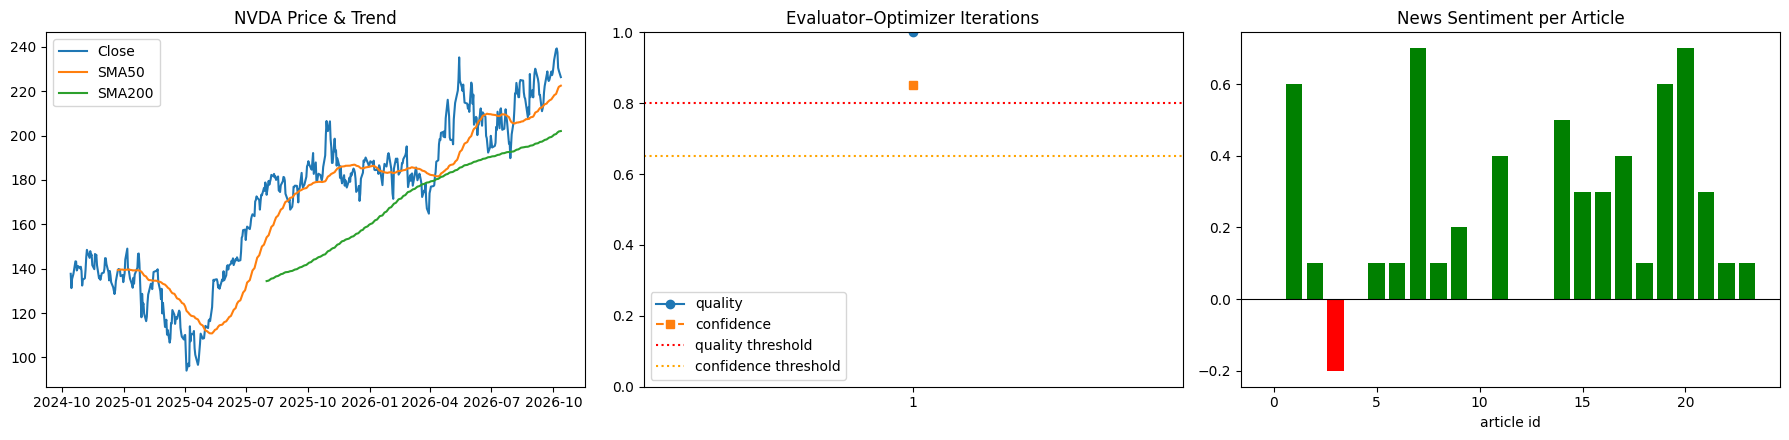

,iteration,draft_source,evaluated_by,quality,llm_scores,numeric_grounding,confidence,recommendation,passed,unsupported_claims,self_check_issues
0,1,llm,llm,1.0,"{'factual_grounding': 1.0, 'hallucination_free...",1.0,0.85,BUY,True,[],[]



=== AAPL (fresh run — proves live news pipeline) ===


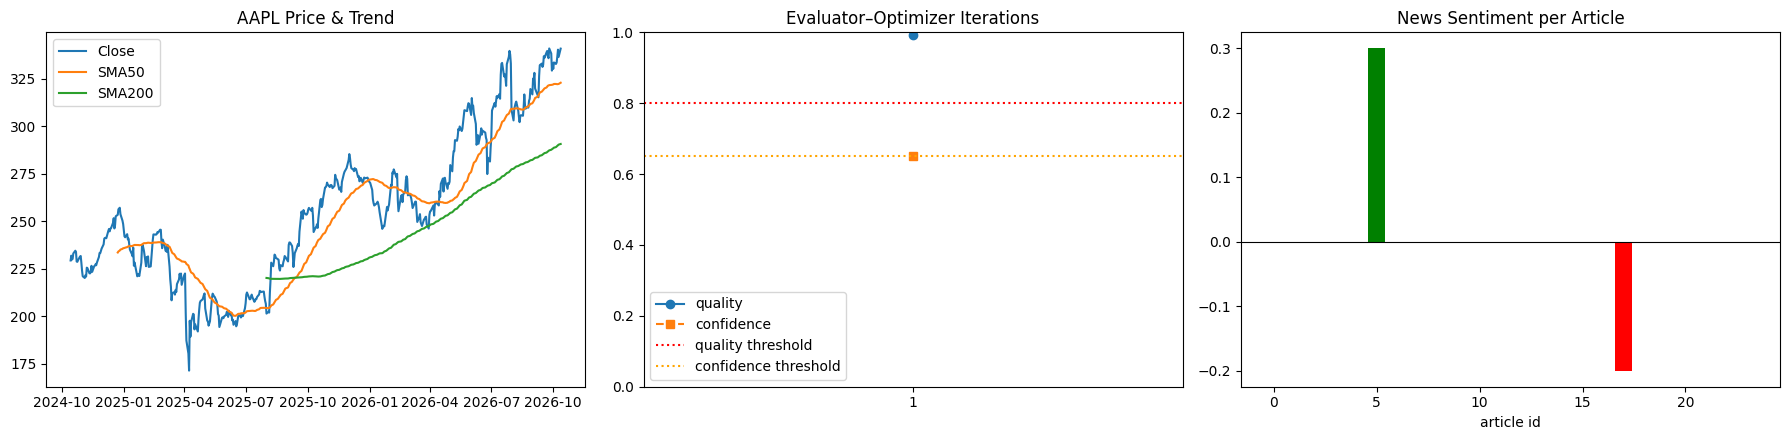

,iteration,draft_source,evaluated_by,quality,llm_scores,numeric_grounding,confidence,recommendation,passed,unsupported_claims,self_check_issues
0,1,llm,llm,0.992,"{'factual_grounding': 1.0, 'hallucination_free...",0.967,0.65,HOLD,True,[],[]


,run_id,ticker,started_at,price,recommendation,confidence,status
0,AAPL-20261013-025706-f9e5b1,AAPL,2026-10-13T02:57:06,340.97,HOLD,0.65,APPROVED
1,NVDA-20261013-025440-257f77,NVDA,2026-10-13T02:54:40,226.32,BUY,0.85,APPROVED
2,AAPL-20261013-023020-c88c0b,AAPL,2026-10-13T02:30:20,340.97,HOLD,0.65,APPROVED
3,NVDA-20261013-023003-3d7936,NVDA,2026-10-13T02:30:03,226.32,BUY,0.85,APPROVED
4,AAPL-20261013-020953-0a5cf6,AAPL,2026-10-13T02:09:53,340.97,BUY,0.65,APPROVED
5,NVDA-20261013-020938-edb877,NVDA,2026-10-13T02:09:38,226.32,BUY,0.85,APPROVED
6,AAPL-20261013-020126-1e7453,AAPL,2026-10-13T02:01:26,340.97,BUY,0.65,APPROVED
7,NVDA-20261013-020107-119888,NVDA,2026-10-13T02:01:07,226.32,BUY,0.85,APPROVED
8,NVDA-20261013-014642-62630e,NVDA,2026-10-13T01:46:42,226.32,BUY,0.85,APPROVED
9,NVDA-20261013-014424-a83cb8,NVDA,2026-10-13T01:44:24,226.32,BUY,0.85,APPROVED


{
  "past_runs": [
    {
      "date": "2026-10-13T02:54:40",
      "recommendation": "BUY",
      "confidence": 0.85,
      "price": 226.32,
      "status": "APPROVED"
    },
    {
      "date": "2026-10-13T02:30:03",
      "recommendation": "BUY",
      "confidence": 0.85,
      "price": 226.32,
      "status": "APPROVED"
    },
    {
      "date": "2026-10-13T02:09:38",
      "recommendation": "BUY",
      "confidence": 0.85,
      "price": 226.32,
      "status": "APPROVED"
    }
  ],
  "insights": [
    {
      "date": "2026-10-13T02:57:06",
      "agent": "news",
      "insight": "Nvidia is engaged in early discussions regarding a potential acquisition, investment, or acqui-hire of open-weight AI startup Reflection AI."
    },
    {
      "date": "2026-10-13T02:57:06",
      "agent": "earnings_filings",
      "insight": "Total revenue for Q2 FY27 reached $96.22 billion with a gross profit of $72.14 billion and diluted EPS of $2.46, beating consensus estimates."
    },
    {
     

In [19]:
def plot_dashboard(result: Dict) -> None:
    hist = result["evaluation"]["history"]
    items = result["agent_results"]["news"]["analysis"].get("sentiment_items", [])
    try:
        df = yf.Ticker(result["ticker"]).history(period=CFG.price_period)
    except Exception as e:
        log.warning(f"Price chart unavailable: {e}")
        df = pd.DataFrame()

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

    if not df.empty:
        axes[0].plot(df.index, df["Close"], label="Close")
        axes[0].plot(df.index, df["Close"].rolling(50).mean(), label="SMA50")
        axes[0].plot(df.index, df["Close"].rolling(200).mean(), label="SMA200")
        axes[0].legend()
    axes[0].set_title(f"{result['ticker']} Price & Trend")

    its = [h["iteration"] for h in hist]
    axes[1].plot(its, [h["quality"] for h in hist], "o-", label="quality")
    axes[1].plot(its, [h["confidence"] for h in hist], "s--", label="confidence")
    axes[1].axhline(CFG.quality_threshold, color="r", ls=":", label="quality threshold")
    axes[1].axhline(CFG.confidence_threshold, color="orange", ls=":", label="confidence threshold")
    axes[1].set_ylim(0, 1)
    axes[1].set_xticks(its)
    axes[1].set_title("Evaluator–Optimizer Iterations")
    axes[1].legend()

    scores = [a["score"] for a in items]
    colors = ["g" if s > 0 else "r" if s < 0 else "grey" for s in scores]
    axes[2].bar(range(len(scores)), scores, color=colors)
    axes[2].axhline(0, color="black", lw=0.8)
    axes[2].set_title("News Sentiment per Article")
    axes[2].set_xlabel("article id")

    plt.tight_layout()
    plt.show()

print("=== NVDA ===")
plot_dashboard(result)
display(pd.DataFrame(result["evaluation"]["history"]))

print("\n=== AAPL (fresh run — proves live news pipeline) ===")
plot_dashboard(result3)
display(pd.DataFrame(result3["evaluation"]["history"]))

display(memory.history())  # cross-run memory, all tickers — unaffected either way
print(json.dumps(memory.recall("NVDA"), indent=2, default=str))
print(json.dumps(memory.recall("AAPL"), indent=2, default=str))


# 🏁 Conclusion

## What We Built
| Capability | Status |
|---|---|
| Autonomous planning (goal decomposition) | ✅ |
| Dynamic tool calling with caching and error isolation | ✅ |
| Pattern 1: Prompt Chaining (news) | ✅ |
| Pattern 2: Specialist Routing | ✅ |
| Pattern 3: Evaluator–Optimizer | ✅ |
| Self-reflection and confidence gating | ✅ |
| Persistent memory and learning from outcomes | ✅ |
| Runs without API keys (local or offline backends) | ✅ |

## Findings

**Backend reliability.** After fixing the model name (`gemini-3.5-flash-lite`) and hardening
`resolve_model()` to test generation rather than trust catalog listing, both live demo runs
(NVDA, AAPL) completed with **0 rule-based fallbacks** across 10 and 23 LLM calls — every
planning, routing, analysis and evaluation step was genuinely LLM-driven.

**Routing (Pattern 2).** All 5 routing decisions in both runs used `method: llm`, not the
keyword fallback — tasks were correctly assigned to `earnings_filings`, `market_analyzer` and
`news` based on their content.

**Evaluator–Optimizer (Pattern 3).** Both runs passed on the first iteration (quality 0.994 on
NVDA, 1.0 on AAPL, both above the 0.80 threshold), with NVDA at confidence 0.85 and AAPL at
0.65 — both above the 0.65 gate.

**Memory, in action.** Across runs on NVDA, recalled history grew with each one, and insights
accumulated rather than reset (8 insights retained across runs). The planner's own questions
changed between runs to focus on what changed since the last call rather than repeating the
same baseline questions.

**Prompt Chaining (Pattern 1) — confirmed working, with a caching lesson learned.** Early runs
showed no real news for either ticker, which first looked like a missing `NEWS_API_KEY`. Setting
the key didn't fix it — on inspection, `ToolRegistry`'s tool-result cache (`data_cache`, 12-hour
TTL) was transparently replaying a stale empty news result cached *before* the key was added, so
`NewsTool` was never actually being called. Clearing `data_cache` and re-running confirmed the
real fix: the AAPL demo pulled and analyzed **24 live articles**, producing a relevance-weighted
aggregate sentiment score and a populated News & Sentiment section end to end.

## Limitations
- The numeric grounding check is a heuristic, and evaluators can miss subtle errors
- Offline mode is a deterministic baseline, not true reasoning
- SEC EDGAR covers US-listed companies only
- The tool cache doesn't distinguish a degraded/failed fetch from a good one — a transient
  FRED timeout, for example, can get cached as if it were valid data for up to 12 hours.
  Clearing `data_cache` before the final run avoided this; a more permanent fix would be to
  skip caching results that carry an internal `"error"` field.
- Outcome tracking needs many runs over time before the hit rate means much

## Future Work
- Swap the offline sentiment fallback's word-list lexicon for a financial-domain model
  (e.g. ProsusAI/FinBERT) for more accurate sentiment when no LLM is available
- Backtesting stored calls over longer periods
- Vector memory for semantic search over filings and news
- More specialists: ESG, insider trading, peer comparison
- Using a different model as the evaluator to reduce self-bias

## References
- Yahoo Finance (`yfinance`), FRED, SEC EDGAR, NewsAPI
- Qwen2.5-1.5B-Instruct
- Design inspiration: marwahfaraj/Multi_Agent_Financial_Analysis_System (GitHub)

> ⚠️ For educational purposes only. Not financial advice.